<a href="https://colab.research.google.com/github/Nathanamarante/ResistoMap/blob/main/ResistoMap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ResistoMap

---

Objetivo: Mapeamento de genes de resistência a antibióticos presentes na Salmonella enterica

# Checklist

Etapas para elaboração:

3. Selecionar e obter os dados

CARD (card.mcmaster.ca): banco de referência com sequências e ontologia dos genes de resistência.
NCBI Pathogen Detection / NCBI Datasets: genomas e metadados (espécie, país, ano, fonte do isolado), com genes AMR já anotados em muitos casos.

ResFinder / AMRFinderPlus: bases e ferramentas alternativas para comparação.

Documentem os critérios de seleção (espécie, qualidade do assembly, período).

### *CHECKLIST: X (Baixado CARD (Referência) e NCBI)

4. Preparar o ambiente
Python com Biopython, pandas, numpy, matplotlib/seaborn, scipy e, opcionalmente, networkx e scikit-learn. Usem Jupyter ou Colab e um repositório no GitHub.

### *CHECKLIST: X

5. Pré-processamento e controle de qualidade

Filtrar genomas por completude, número de contigs e metadados faltantes.
Padronizar nomes de espécies, países e datas.
Remover duplicatas.

### *CHECKLIST: X

6. Identificar os genes de resistência
Há duas abordagens, e pode-se combinar ambas:

Usar ferramentas prontas (RGI do CARD ou AMRFinderPlus) e processar a saída em Python.
Implementar uma busca própria: alinhar ou procurar as sequências do CARD nos genomas (por exemplo, com BLAST local e filtros de identidade e cobertura). Isso vai reforçar o lado algorítmico da disciplina.

### *CHECKLIST: X

7. Construir a matriz presença/ausência
Montar uma tabela genomas × genes (0/1), a base de todas as análises seguintes.

### *CHECKLIST: X

8. Análises exploratórias e estatísticas

Prevalência de cada gene e de cada classe de antibiótico.
Número médio de genes de resistência por genoma.
Comparação entre grupos (países, anos, fontes: hospitalar, ambiental, animal), com testes estatísticos como qui-quadrado.
Coocorrência de genes (correlação ou índice de Jaccard) e rede de coocorrência.
Agrupamento hierárquico de genomas por perfil de resistência.

### *CHECKLIST: A FAZER

9. Análise avançada (opcional)

PCA ou UMAP sobre a matriz de perfis.
Modelo de machine learning para prever o fenótipo (resistente/sensível) a partir dos genes, com validação cruzada.
Identificação de genomas multirresistentes (MDR).

### *CHECKLIST: A FAZER

10. Visualização dos resultados
Barras de prevalência, heatmap de presença/ausência, mapa ou série temporal, rede de coocorrência e dendrograma.

### *CHECKLIST: A FAZER

11. Interpretação biológica e limitações
Relacionem os achados com a literatura e com a saúde pública. Discutam vieses: genomas de hospitais estão super-representados, e a presença do gene não garante expressão ou resistência fenotípica.

### *CHECKLIST: A FAZER

12. Documentação e reprodutibilidade
README, notebook organizado, lista de dependências e instruções para reproduzir.

### *CHECKLIST: A FAZER

13. Preparar o seminário
Roteiro sugerido: problema → dados → método → resultados → conclusões e limitações. Reservem tempo para ensaiar e dividam as falas entre os integrantes.

### *CHECKLIST: A FAZER

Critérios de seleção dos dados:
Salmonella enterica

Localização: Brazil

Qualidade do Assembly: Não filtrado (Revisar durante o desenvolvimento)

Período: sem restrição de data

_______________________________________________________________________________
Arquivos do CARD Dataset (Referência) são genomas (FASTA). As variantes no NCBI estão em FNA)

_______________________________________________________________________________

Decisão sobre cada arquivo utilizado:
Espécie diferente de Salmonella enterica =	Excluir

Arquivo vazio ou corrompido =	Excluir

Tamanho muito abaixo de 3,5 Mb =	Excluir ou revisar

País faltando, mas análise será por país =	Excluir ou colocar em grupo “desconhecido”

Ano faltando, mas análise será temporal =	Excluir ou colocar em grupo “desconhecido”

Duplicata exata =	Manter apenas uma

Duplicata quase idêntica =	Escolher a de melhor qualidade

______________________________________________________

# Rodar todas as bibliotecas primeiro para não dar erro no código 📢⚠️

# Adicionando bibiotecas e Google Drive

In [5]:
!pip install biopython pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 7.0 MB/s  0:00:00


In [6]:
# Módulo OS
import os

#Módulo Sys
import sys

# Módulo CSV
import csv

# Módulo RE
import re

# Argparse
import argparse

# Hashlib
import hashlib

# Json
import json

# Datetime
from datetime import datetime

# Subprocess
import subprocess


# Biblioteca para bioinformática (manipulação de arquivos FASTA, GenBank, etc.)
import Bio
from Bio import SeqIO, Align
from Bio.SeqUtils import gc_fraction

# Bibliotecas para manipulação e análise de dados estruturados
import pandas as pd
import numpy as np

# Bibliotecas para análise estatística e matemática
import scipy
from scipy import stats

# Bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas opcionais para grafos/redes e Machine Learning
import networkx as nx
import sklearn

# Confirmando as versões instaladas
print("Biopython versão:", Bio.__version__)
print("Pandas versão:", pd.__version__)

Biopython versão: 1.88
Pandas versão: 2.2.3


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap


/content/drive/MyDrive/Colab Notebooks/ResistoMap


______________________________________________________

# Leitura Metadados/CSV CARD (Referência)
- Vamos ter que fazer leitura dos arquivos FASTA e desenvolver o arquivo com metadados CSV

In [7]:
%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)

/content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)


In [8]:
'''
Código abaixo foi desenvolvido para ler os arquivos de resistência a antimicrobianos
disponíveis em formato FASTA, baixados do card.mcmaster.ca utilizado como referência
E gerar um arquivo chamado ids_card_extraidos.csv para buscar os metadados no site do CARD

'''
# ============================================================================

''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO

# --- CONFIGURAÇÃO ---
# Coloque o caminho da pasta onde estão os arquivos FASTA a serem trabalhados
caminho_da_pasta = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)"
nome_do_csv = "ids_card_extraidos.csv" #Nome do arquivo csv gerado ao final

def extrair_ids_card(pasta_origem, arquivo_saida):
    """
    Lê todos os arquivos FASTA em uma pasta e extrai os IDs únicos.

    Args:
        pasta_origem (str): Caminho da pasta onde estão os arquivos .fasta
        arquivo_saida (str): Nome do arquivo CSV de saída
    """
    ids_encontrados = set()  # Usamos um set para garantir que os IDs sejam únicos

    # Listar arquivos na pasta
    arquivos = [f for f in os.listdir(pasta_origem) if f.endswith(('.fasta', '.fa', '.fna'))]

    if not arquivos:
        print(f"Nenhum arquivo .fasta encontrado na pasta: {pasta_origem}")
        return

    print(f"Iniciando leitura de {len(arquivos)} arquivos...")

    for nome_arquivo in arquivos:
        caminho_completo = os.path.join(pasta_origem, nome_arquivo)
        try:
            # SeqIO.parse lê o arquivo e retorna um iterador de registros
            for registro in SeqIO.parse(caminho_completo, "fasta"):
                # O .id geralmente contém o ID do CARD (ex: CARD_000001)
                # Se o ID estiver no cabeçalho mas não no .id, usamos registro.description
                id_sequencia = registro.id
                ids_encontrados.add(id_sequencia)
        except Exception as e:
            print(f"Erro ao ler o arquivo {nome_arquivo}: {e}")

    # Converter o set para uma lista ordenada para salvar no CSV
    lista_ids = sorted(list(ids_encontrados))

    # Salvar em CSV
    try:
        with open(arquivo_saida, mode='w', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            writer.writerow(['CARD_ID']) # Cabeçalho
            for id_item in lista_ids:
                writer.writerow([id_item])

        print(f"Sucesso! {len(lista_ids)} IDs únicos foram extraídos.")
        print(f"Os dados foram salvos em: {arquivo_saida}")
    except Exception as e:
        print(f"Erro ao salvar o arquivo CSV: {e}")

# Executar a função
extrair_ids_card(caminho_da_pasta, nome_do_csv)


_IncompleteInputError: incomplete input (100285677.py, line 8)

In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos

"""
Cruzamento de IDs extraídos (ids_card_extraidos.csv) com os metadados do CARD
(aro_index.tsv + nucleotide_fasta_protein_homolog_model.fasta).

Se os arquivos ainda não estiverem no Colab, vai aparecer o botão de upload.
Saída: metadados_card_final.csv (baixado automaticamente no Colab).
"""
''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO
# =============================== CONFIGURAÇÃO ===============================
ARQ_IDS = "ids_card_extraidos.csv"
ARQ_INDEX = "aro_index.tsv"
ARQ_FASTA = "nucleotide_fasta_protein_homolog_model.fasta"
ARQ_SAIDA = "metadados_card_final.csv"

SEP_SAIDA = ","            # use ";" se for abrir direto no Excel em português
TOLERANCIA_COORD = 1       # CARD usa início 0-based; seus IDs podem usar 1-based
INCLUIR_COLUNAS_AUDITORIA = False   # True = acrescenta tipo/confiança/observação

# Colunas de metadados que vão para o CSV final (nomes do aro_index.tsv)
COLUNAS_METADADOS = [
    "ARO Accession", "ARO Name", "CARD Short Name",
    "Protein Accession", "DNA Accession",
    "AMR Gene Family", "Drug Class", "Resistance Mechanism",
]

# Desempate manual para IDs de nucleotídeo cujo accession tem vários modelos no
# índice e cuja coordenada não consta no FASTA (modelos de variante/mutação).
# Chave = ID original; valor = trecho do "ARO Name" que identifica o gene.
# Atribuições inferidas pelo tamanho do intervalo; confirme no NCBI.
RESOLUCAO_MANUAL = {
    "gb|AE006468.2|2373710-2376346|Salmonella": "gyrA",
    "gb|AE006468.2|3336954-3339212|Salmonella": "parC",
}
# ============================================================================


def garantir_arquivos():
    """No Colab, abre o upload se algum arquivo estiver faltando."""
    faltando = [a for a in (ARQ_IDS, ARQ_INDEX, ARQ_FASTA) if not os.path.exists(a)]
    if not faltando:
        return
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Arquivos não encontrados na pasta atual: {faltando}")
    print("Envie os arquivos:", faltando)
    files.upload()  # grava na pasta atual do Colab
    faltando = [a for a in faltando if not os.path.exists(a)]
    if faltando:
        raise FileNotFoundError(
            f"Ainda faltam: {faltando}. Se o Colab renomeou (ex.: 'arquivo (1).tsv'), "
            "ajuste os nomes na seção CONFIGURAÇÃO."
        )


def sem_versao(acc):
    return acc.split(".")[0]


def interpretar_id(cid):
    """Extrai accession, intervalo (ou '') e ARO (ou '') de um ID do tipo
    gb|ACESSO|[+|-|]inicio-fim|[ARO:xxxx|]Nome."""
    partes = [p.strip() for p in cid.split("|")]
    acc = partes[1] if len(partes) > 1 else partes[0]
    intervalo = next((p for p in partes if re.fullmatch(r"\d+-\d+", p)), "")
    aro = next((p for p in partes if p.startswith("ARO:")), "")
    return acc, intervalo, aro


def ler_fasta_headers(caminho):
    """Retorna {accession: [(inicio, fim, fita, ARO), ...]} a partir dos cabeçalhos."""
    mapa = {}
    with open(caminho, encoding="utf-8", errors="replace") as fh:
        for linha in fh:
            if not linha.startswith(">"):
                continue
            p = linha[1:].strip().split("|")
            if len(p) < 5 or not re.fullmatch(r"\d+-\d+", p[3]):
                continue
            ini, fim = map(int, p[3].split("-"))
            mapa.setdefault(p[1], []).append((ini, fim, p[2], p[4]))
    return mapa


# --------------------------------- carga ------------------------------------
garantir_arquivos()

ids = pd.read_csv(ARQ_IDS, dtype=str)
col_id = "CARD_ID" if "CARD_ID" in ids.columns else ids.columns[0]
ids = ids[[col_id]].rename(columns={col_id: "CARD_ID"})
ids["CARD_ID"] = ids["CARD_ID"].str.strip()
ids = ids.dropna().drop_duplicates().reset_index(drop=True)

idx = pd.read_csv(ARQ_INDEX, sep="\t", dtype=str).fillna("")
fasta = ler_fasta_headers(ARQ_FASTA)

# Proteínas citadas na própria lista (ajudam a desempatar accessions de DNA)
prot_na_lista = {
    interpretar_id(c)[0] for c in ids["CARD_ID"] if not interpretar_id(c)[1]
}

print(f"IDs de entrada: {len(ids)} | modelos no aro_index: {len(idx)} | "
      f"accessions com coordenada no FASTA: {len(fasta)}\n")


# ------------------------------- cruzamento ---------------------------------
def buscar(cid):
    """Retorna (DataFrame de modelos, tipo, confiança, observação)."""
    acc, intervalo, aro = interpretar_id(cid)
    base = sem_versao(acc)

    # 1) o próprio ID já traz o ARO
    if aro:
        m = idx[idx["ARO Accession"] == aro]
        if len(m):
            return m, "ARO no ID", "Alta", ""

    # 2) ID de proteína (sem intervalo)
    if not intervalo:
        m = idx[idx["Protein Accession"] == acc]
        if len(m):
            obs = f"Ligado a {len(m)} modelos ARO." if len(m) > 1 else ""
            return m, "Protein Accession", "Alta", obs
        m = idx[idx["Protein Accession"].map(sem_versao) == base]
        if len(m):
            return m, "Protein Accession (sem versão)", "Média", "Versão do accession difere."
        m = idx[idx["DNA Accession"].map(sem_versao) == base]
        if len(m):
            return m, "DNA Accession", "Média", "Sem intervalo; todos os modelos do accession."
        return idx.iloc[0:0], "SEM CORRESPONDÊNCIA", "", "Accession não consta no aro_index."

    # 3) ID de nucleotídeo com intervalo: tenta casar a coordenada no FASTA
    ini, fim = map(int, intervalo.split("-"))
    for f_ini, f_fim, fita, f_aro in fasta.get(acc, []):
        if abs(f_ini - ini) <= TOLERANCIA_COORD and f_fim == fim:
            m = idx[idx["ARO Accession"] == f_aro]
            if len(m):
                return m, "Coordenada no FASTA", "Alta", f"FASTA: {f_ini}-{f_fim} (fita {fita})."

    # 4) DNA Accession no índice
    m = idx[idx["DNA Accession"] == acc]
    if m.empty:
        m = idx[idx["DNA Accession"].map(sem_versao) == base]
    if m.empty:
        return idx.iloc[0:0], "SEM CORRESPONDÊNCIA", "", "Accession não consta no aro_index."
    if len(m) == 1:
        return m, "DNA Accession (único)", "Alta", f"Único modelo para {acc}."

    # 4b) vários modelos: desempate manual
    gene = RESOLUCAO_MANUAL.get(cid)
    if gene:
        mm = m[m["ARO Name"].str.contains(gene, case=False, regex=False)]
        if len(mm):
            return mm, "DNA Accession + manual", "Média", \
                f"{len(m)} modelos em {acc}; atribuído a '{gene}' manualmente. Confirmar."

    # 4c) vários modelos: usa proteínas presentes na lista
    mm = m[m["Protein Accession"].isin(prot_na_lista)]
    if 0 < len(mm) < len(m):
        return mm, "DNA Accession + proteínas da lista", "Baixa", \
            f"{len(m)} modelos em {acc}; restrito às proteínas da sua lista. AMBÍGUO."
    return m, "DNA Accession (ambíguo)", "Baixa", f"{len(m)} modelos em {acc}. AMBÍGUO."


resultados = []
for cid in ids["CARD_ID"]:
    m, tipo, conf, obs = buscar(cid)
    if m.empty:
        linha = {"CARD_ID": cid, **{c: "" for c in COLUNAS_METADADOS}}
        linha.update(Tipo_correspondencia=tipo, Confianca=conf, Observacao=obs)
        resultados.append(linha)
        continue
    for _, r in m.iterrows():
        linha = {"CARD_ID": cid, **{c: r[c] for c in COLUNAS_METADADOS}}
        linha.update(Tipo_correspondencia=tipo, Confianca=conf, Observacao=obs)
        resultados.append(linha)

final = pd.DataFrame(resultados).drop_duplicates().reset_index(drop=True)

# ------------------------------- relatório ----------------------------------
print("Resumo por tipo de correspondência:")
print(final.groupby(["Tipo_correspondencia", "Confianca"]).size().to_string(), "\n")

sem = final[final["Tipo_correspondencia"] == "SEM CORRESPONDÊNCIA"]["CARD_ID"].tolist()
if sem:
    print("IDs SEM correspondência:", *sem, sep="\n  - ")
revisar = final[final["Confianca"].isin(["Média", "Baixa"])]
if len(revisar):
    print("\nIDs para revisar manualmente (confiança Média/Baixa):")
    print(revisar[["CARD_ID", "ARO Name", "Confianca", "Observacao"]].to_string(index=False))

# --------------------------------- saída ------------------------------------
saida = final if INCLUIR_COLUNAS_AUDITORIA else final[["CARD_ID"] + COLUNAS_METADADOS]
saida.to_csv(ARQ_SAIDA, index=False, sep=SEP_SAIDA, encoding="utf-8-sig")
print(f"\nArquivo gerado: {ARQ_SAIDA} ({len(saida)} linhas, {saida['CARD_ID'].nunique()} IDs distintos)")

try:
    from google.colab import files
    files.download(ARQ_SAIDA)
except ImportError:
    pass


In [ ]:
''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO
%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Metadados CARD final

df = pd.read_csv("metadados_card_final.csv") #Arquivos do CARD (Referência) só estão presentes em FASTA, foi necessário buscar os metadados

print(df.shape)
print(df.columns)
print(df.head())
print(df.dtypes)
print(df.isna().sum())


In [ ]:
''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO

# Para evitar conflitos de variáveis, carregamos o dataset do NCBI em uma variável específica
card_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/NCBI dataset isolates.csv")

# 1. Espécie (Organism group)
print("=== Organism group ===")
print(card_df["#Organism group"].value_counts(dropna=False))

# 2. País (Location)
print("\n=== Location (Country) ===")
print(card_df["Location"].value_counts(dropna=False))

# 3. Ano (Extraído de 'Create date')
card_df['Year'] = card_df['Create date'].astype(str).str[:4]
print("\n=== Year ===")
print(card_df['Year'].value_counts(dropna=False))

# 4. Fonte de Isolamento (Isolation source ou Isolation type)
print("\n=== Isolation source ===")
print(card_df["Isolation source"].value_counts(dropna=False))

In [ ]:
"""
Leitura e consolidação dos metadados do CARD para uso como
referência no projeto (genes de resistência em Salmonella enterica / S. bongori).

Fontes (pacote "card-data" de https://card.mcmaster.ca/download):
  - aro_index.tsv                                 -> TODAS as 12 colunas são mantidas
  - nucleotide_fasta_protein_homolog_model.fasta  -> cabeçalhos (organismo, fita,
                                                     coordenadas, nome) + comprimento

Saídas (pasta --saida):
  - referencia_card_completa.csv    tabela de referência completa (sem descartar colunas)
  - referencia_card_salmonella.csv  subconjunto marcado como Salmonella
  - referencia_card_manifest.json   rastreabilidade (hash dos insumos, contagens, data)

Uso no Colab (célula única):   exec(open("card_reference.py").read())   ou cole o código.
Uso como módulo:
    from card_reference import carregar_referencia, CardReference
    ref = CardReference(carregar_referencia("aro_index.tsv", "nucleotide_fasta_....fasta"))
    ref.por_aro("ARO:3002691");  ref.por_accession("AAL21173.1");  ref.salmonella()
"""

''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO

%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos

# =============================== CONFIGURAÇÃO ===============================
ARQ_INDEX = "aro_index.tsv"
ARQ_FASTA = "nucleotide_fasta_protein_homolog_model.fasta"
PASTA_SAIDA = "."
VERSAO_CARD = ""            # preencha (ex.: "4.0.1") - o aro_index/FASTA não informam a versão
INCLUIR_SEQUENCIA = False   # True = coluna 'sequencia' no CSV (arquivo bem maior)
ENCODING_SAIDA = "utf-8-sig"
# ============================================================================

COLUNAS_INDEX_ESPERADAS = [
    "ARO Accession", "CVTERM ID", "Model Sequence ID", "Model ID", "Model Name",
    "ARO Name", "Protein Accession", "DNA Accession", "AMR Gene Family",
    "Drug Class", "Resistance Mechanism", "CARD Short Name",
]
RE_INTERVALO = re.compile(r"\d+-\d+")
RE_NOME_ORG = re.compile(r"^(.*)\[([^\]]+)\]\s*(.*)$")   # último [colchete] = organismo


# ------------------------------- utilidades ---------------------------------
def sha256(caminho, bloco=1 << 20):
    h = hashlib.sha256()
    with open(caminho, "rb") as fh:
        for parte in iter(lambda: fh.read(bloco), b""):
            h.update(parte)
    return h.hexdigest()


def normalizar_aro(valor):
    """'3002691' ou 'ARO:3002691' -> 'ARO:3002691'."""
    valor = str(valor).strip()
    return valor if valor.startswith("ARO:") else f"ARO:{valor}"


def sem_versao(acc):
    return str(acc).split(".")[0]


def classificar_salmonella(texto):
    """Retorna o rótulo de táxon encontrado em um texto, ou ''."""
    if not isinstance(texto, str) or "Salmonella" not in texto:
        return ""
    if re.search(r"Salmonella\s+enterica", texto):
        return "Salmonella enterica"
    if re.search(r"Salmonella\s+bongori", texto):
        return "Salmonella bongori"
    return "Salmonella (espécie não especificada)"


# --------------------------------- leitura ----------------------------------
def ler_aro_index(caminho):
    """Lê o aro_index.tsv inteiro, como texto (nada é convertido nem descartado)."""
    df = pd.read_csv(caminho, sep="\t", dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    faltando = [c for c in COLUNAS_INDEX_ESPERADAS if c not in df.columns]
    if faltando:
        raise ValueError(f"{caminho}: colunas esperadas ausentes: {faltando}")
    return df


def ler_fasta(caminho, incluir_sequencia=False):
    """Lê o FASTA em streaming. Cabeçalho CARD:
         >gb|ACESSO|FITA|INICIO-FIM|ARO:xxxxxxx|Nome [Organismo] [Sufixo]
    Retorna (DataFrame, lista de cabeçalhos fora do padrão)."""
    registros, fora_padrao = [], []
    atual, comp, seq = None, 0, []

    def fechar():
        if atual is not None:
            atual["comprimento_pb"] = comp
            if incluir_sequencia:
                atual["sequencia"] = "".join(seq)
            registros.append(atual)

    with open(caminho, encoding="utf-8", errors="replace") as fh:
        for linha in fh:
            if linha.startswith(">"):
                fechar()
                comp, seq = 0, []
                cab = linha[1:].rstrip("\r\n")
                p = cab.split("|", 5)
                if len(p) == 6 and RE_INTERVALO.fullmatch(p[3]) and p[4].startswith("ARO:"):
                    ini, fim = p[3].split("-")
                    m = RE_NOME_ORG.match(p[5])
                    nome, org, suf = (m.group(1).strip(), m.group(2).strip(), m.group(3).strip()) \
                        if m else (p[5].strip(), "", "")
                    atual = {
                        "fasta_accession": p[1], "fasta_fita": p[2],
                        "fasta_inicio": int(ini), "fasta_fim": int(fim),
                        "fasta_aro": p[4], "fasta_nome": nome,
                        "fasta_organismo": org, "fasta_sufixo": suf,
                        "fasta_header": cab,
                    }
                else:
                    fora_padrao.append(cab)
                    atual = {"fasta_header": cab}
            elif atual is not None:
                s = linha.strip()
                comp += len(s)
                if incluir_sequencia:
                    seq.append(s)
    fechar()
    df = pd.DataFrame(registros)
    for c in ("fasta_inicio", "fasta_fim"):
        df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
    return df, fora_padrao


# ------------------------------- consolidação -------------------------------
def carregar_referencia(caminho_index=ARQ_INDEX, caminho_fasta=ARQ_FASTA,
                        incluir_sequencia=INCLUIR_SEQUENCIA, verbose=True):
    """Une aro_index + FASTA em uma tabela única, sem perder nenhuma linha de
    nenhum dos dois arquivos (coluna 'origem' indica de onde veio cada linha)."""
    idx = ler_aro_index(caminho_index)
    fasta, fora_padrao = ler_fasta(caminho_fasta, incluir_sequencia)
    idx["_idx_row"] = range(len(idx))
    fasta["_fasta_row"] = range(len(fasta))

    # chave = ARO Accession. Se um ARO tem >1 modelo no índice, prefere-se o
    # modelo cujo DNA Accession coincide com o accession do FASTA.
    m = fasta.merge(idx, left_on="fasta_aro", right_on="ARO Accession", how="left")
    m["acc_consistente"] = m["fasta_accession"] == m["DNA Accession"]
    m["n_modelos_index_por_aro"] = m.groupby("_fasta_row")["_idx_row"].transform("count")
    tem_ok = m.groupby("_fasta_row")["acc_consistente"].transform("any")
    m = m[~(tem_ok & ~m["acc_consistente"])].copy()
    m["origem"] = m["_idx_row"].notna().map({True: "aro_index+fasta", False: "so_fasta"})

    so_idx = idx[~idx["_idx_row"].isin(m["_idx_row"].dropna())].copy()
    so_idx["origem"] = "so_aro_index"
    so_idx["n_modelos_index_por_aro"] = so_idx.groupby("ARO Accession")["_idx_row"].transform("count")

    ref = pd.concat([m, so_idx], ignore_index=True)
    ref["acc_consistente"] = ref["acc_consistente"].where(ref["origem"] == "aro_index+fasta")
    ref["comprimento_pb"] = ref["comprimento_pb"].astype("Int64")
    ref["fasta_ambiguo"] = (ref["origem"] == "aro_index+fasta") & (ref["n_modelos_index_por_aro"] > 1)

    # Salmonella: organismo do FASTA e/ou nome do modelo (ARO Name) no índice
    t_org = ref["fasta_organismo"].map(classificar_salmonella)
    t_nome = ref["ARO Name"].map(classificar_salmonella)
    ref["salmonella_taxon"] = t_org.where(t_org != "", t_nome)
    ref["salmonella_fonte"] = ""
    ref.loc[t_nome != "", "salmonella_fonte"] = "ARO Name"
    ref.loc[t_org != "", "salmonella_fonte"] = "organismo_fasta"
    ref.loc[(t_org != "") & (t_nome != ""), "salmonella_fonte"] = "organismo_fasta+ARO Name"
    ref["eh_salmonella"] = ref["salmonella_taxon"] != ""

    # coordenadas em 1-based (CARD guarda início 0-based; validado em relatorio())
    ref["fasta_inicio_1based"] = ref["fasta_inicio"] + 1

    ordem = (COLUNAS_INDEX_ESPERADAS
             + ["fasta_accession", "fasta_fita", "fasta_inicio", "fasta_inicio_1based", "fasta_fim",
                "comprimento_pb", "fasta_aro", "fasta_nome", "fasta_organismo", "fasta_sufixo",
                "fasta_header", "origem", "acc_consistente", "n_modelos_index_por_aro",
                "fasta_ambiguo", "eh_salmonella", "salmonella_taxon", "salmonella_fonte"]
             + (["sequencia"] if incluir_sequencia else []))
    extras = [c for c in idx.columns if c not in ordem and not c.startswith("_")]
    ref = ref[ordem + extras]
    # ARO de linhas 'so_fasta' (sem índice) permanece em fasta_aro; preenche a chave
    ref["ARO Accession"] = ref["ARO Accession"].where(ref["ARO Accession"].notna(), ref["fasta_aro"])
    ref = ref.fillna({c: "" for c in COLUNAS_INDEX_ESPERADAS + ["fasta_accession", "fasta_fita",
        "fasta_aro", "fasta_nome", "fasta_organismo", "fasta_sufixo", "fasta_header"]})
    ref.attrs["fora_padrao"] = fora_padrao
    ref.attrs["n_idx"], ref.attrs["n_fasta"] = len(idx), len(fasta)
    if verbose:
        relatorio(ref)
    return ref.reset_index(drop=True)


def relatorio(ref):
    """Validações e contagens para conferir a carga."""
    print("=" * 70)
    print(f"linhas do aro_index: {ref.attrs.get('n_idx')} | registros no FASTA: {ref.attrs.get('n_fasta')}")
    print(f"linhas na referência: {len(ref)}")
    print(ref["origem"].value_counts().to_string(), "\n")
    if ref.attrs.get("fora_padrao"):
        print(f"AVISO: {len(ref.attrs['fora_padrao'])} cabeçalho(s) fora do padrão esperado.")
    aros_fasta = set(ref.loc[ref["origem"] != "so_aro_index", "ARO Accession"])
    preteridos = ref[(ref["origem"] == "so_aro_index") & ref["ARO Accession"].isin(aros_fasta)]
    print(f"modelos do índice com ARO presente no FASTA, mas accession diferente do FASTA "
          f"(mantidos como so_aro_index): {len(preteridos)}")
    print(f"linhas ambíguas (registro do FASTA ligado a >1 modelo do índice, mesmo accession): "
          f"{int(ref['fasta_ambiguo'].sum())}")
    print(f"registros do FASTA sem organismo entre colchetes: "
          f"{int(((ref['origem'] != 'so_aro_index') & (ref['fasta_organismo'] == '')).sum())}")
    com_seq = ref[ref["comprimento_pb"].notna() & ref["fasta_inicio"].notna()]
    if len(com_seq):
        ok = ((com_seq["fasta_fim"] - com_seq["fasta_inicio"]) == com_seq["comprimento_pb"]).mean()
        print(f"coordenada (fim - início) == comprimento da sequência: {ok:.1%} "
              "(confirma início 0-based, fim inclusivo)")
    print("\nSalmonella na referência:")
    sal = ref[ref["eh_salmonella"]]
    print(sal["salmonella_taxon"].value_counts().to_string() if len(sal) else "  nenhuma")
    if not (ref["salmonella_taxon"] == "Salmonella bongori").any():
        print("AVISO: nenhum registro de Salmonella bongori nestes dois arquivos "
              "(organismo do FASTA ou ARO Name).")
    print("=" * 70)


# ------------------------------- consultas ----------------------------------
class CardReference:
    """Consultas sobre a tabela de referência."""

    def __init__(self, df):
        self.df = df

    def por_aro(self, aro):
        return self.df[self.df["ARO Accession"] == normalizar_aro(aro)]

    def por_accession(self, acc):
        """Procura em Protein Accession, DNA Accession e accession do FASTA;
        se não achar, tenta sem o sufixo de versão."""
        d = self.df
        m = d[(d["Protein Accession"] == acc) | (d["DNA Accession"] == acc) | (d["fasta_accession"] == acc)]
        if m.empty:
            b = sem_versao(acc)
            m = d[(d["Protein Accession"].map(sem_versao) == b) | (d["DNA Accession"].map(sem_versao) == b)
                  | (d["fasta_accession"].map(sem_versao) == b)]
        return m

    def por_coordenada(self, acc, inicio, fim, tolerancia=1):
        """Casa intervalo (0- ou 1-based no início) com o FASTA."""
        d = self.df
        return d[(d["fasta_accession"] == acc)
                 & ((d["fasta_inicio"] - inicio).abs() <= tolerancia) & (d["fasta_fim"] == fim)]

    def por_id_card(self, cid):
        """Aceita IDs como 'gb|AAL21173.1|Salmonella' ou 'gb|AJ487033.2|1686-2858|Salmonella'."""
        p = [x.strip() for x in cid.split("|")]
        acc = p[1] if len(p) > 1 else p[0]
        rng = next((x for x in p if RE_INTERVALO.fullmatch(x)), "")
        if rng:
            ini, fim = map(int, rng.split("-"))
            m = self.por_coordenada(acc, ini, fim)
            if len(m):
                return m
        return self.por_accession(acc)

    def salmonella(self, taxon=None):
        d = self.df[self.df["eh_salmonella"]]
        return d if taxon is None else d[d["salmonella_taxon"].str.contains(taxon, case=False)]


# --------------------------------- saída ------------------------------------
def salvar(ref, pasta=PASTA_SAIDA, versao_card=VERSAO_CARD, caminho_index=ARQ_INDEX,
           caminho_fasta=ARQ_FASTA):
    os.makedirs(pasta, exist_ok=True)
    f_comp = os.path.join(pasta, "referencia_card_completa.csv")
    f_sal = os.path.join(pasta, "referencia_card_salmonella.csv")
    f_man = os.path.join(pasta, "referencia_card_manifest.json")
    ref.to_csv(f_comp, index=False, encoding=ENCODING_SAIDA)
    ref[ref["eh_salmonella"]].to_csv(f_sal, index=False, encoding=ENCODING_SAIDA)
    manifest = {
        "gerado_em": datetime.now().isoformat(timespec="seconds"),
        "versao_card_informada": versao_card or "NÃO INFORMADA",
        "insumos": {os.path.basename(p): {"sha256": sha256(p), "bytes": os.path.getsize(p)}
                    for p in (caminho_index, caminho_fasta)},
        "linhas_aro_index": ref.attrs.get("n_idx"),
        "registros_fasta": ref.attrs.get("n_fasta"),
        "linhas_referencia": len(ref),
        "por_origem": ref["origem"].value_counts().to_dict(),
        "salmonella_por_taxon": ref[ref["eh_salmonella"]]["salmonella_taxon"].value_counts().to_dict(),
    }
    with open(f_man, "w", encoding="utf-8") as fh:
        json.dump(manifest, fh, ensure_ascii=False, indent=2)
    return f_comp, f_sal, f_man


def garantir_arquivos(caminhos):
    """No Colab, abre o upload caso algum arquivo falte."""
    faltando = [c for c in caminhos if not os.path.exists(c)]
    if not faltando:
        return
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Arquivos não encontrados: {faltando}")
    print("Envie os arquivos:", faltando)
    files.upload()
    faltando = [c for c in faltando if not os.path.exists(c)]
    if faltando:
        raise FileNotFoundError(f"Ainda faltam: {faltando}")


def main(argv=None):
    ap = argparse.ArgumentParser(description="Consolida a referência CARD (aro_index + FASTA).")
    ap.add_argument("--index", default=ARQ_INDEX)
    ap.add_argument("--fasta", default=ARQ_FASTA)
    ap.add_argument("--saida", default=PASTA_SAIDA)
    ap.add_argument("--versao-card", default=VERSAO_CARD)
    ap.add_argument("--com-sequencia", action="store_true", default=INCLUIR_SEQUENCIA)
    args, _ = ap.parse_known_args(argv)   # parse_known_args: tolera os argumentos do Colab/Jupyter
    garantir_arquivos([args.index, args.fasta])
    ref = carregar_referencia(args.index, args.fasta, args.com_sequencia)
    arquivos = salvar(ref, args.saida, args.versao_card, args.index, args.fasta)
    print("Arquivos gerados:", *arquivos, sep="\n  - ")
    if not args.versao_card:
        print("\nAviso: informe --versao-card (ou VERSAO_CARD) para registrar a versão do CARD no manifest.")
    return ref


if __name__ == "__main__":
    referencia = main(sys.argv[1:])

* Leitura Metadados CARD Final

In [10]:
%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos/Referências CARD

# Carregar a referência consolidada do CARD que foi gerada anteriormente
card_ref_df = pd.read_csv("referencia_card_completa.csv")

print("=== Estrutura do Dataset CARD ===")
print("Formato:", card_ref_df.shape)
print("\nColunas:", list(card_ref_df.columns))
print("\nTipos de dados:\n", card_ref_df.dtypes)
print("\nValores nulos por coluna:\n", card_ref_df.isna().sum())

# 1. Espécie / Táxon identificado como Salmonella
print("\n=== Distribuição de Táxons de Salmonella ===")
print(card_ref_df["salmonella_taxon"].value_counts(dropna=False))

# 2. Família de Genes de Resistência (AMR Gene Family)
print("\n=== Principais Famílias de Genes AMR ===")
print(card_ref_df["AMR Gene Family"].value_counts(dropna=False).head(15))

# 3. Classe de Droga (Drug Class)
print("\n=== Classes de Antibióticos Alvo ===")
print(card_ref_df["Drug Class"].value_counts(dropna=False).head(15))

# 4. Mecanismo de Resistência (Resistance Mechanism)
print("\n=== Mecanismos de Resistência ===")
print(card_ref_df["Resistance Mechanism"].value_counts(dropna=False))

/content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos/Referências CARD
=== Estrutura do Dataset CARD ===
Formato: (6463, 30)

Colunas: ['ARO Accession', 'CVTERM ID', 'Model Sequence ID', 'Model ID', 'Model Name', 'ARO Name', 'Protein Accession', 'DNA Accession', 'AMR Gene Family', 'Drug Class', 'Resistance Mechanism', 'CARD Short Name', 'fasta_accession', 'fasta_fita', 'fasta_inicio', 'fasta_inicio_1based', 'fasta_fim', 'comprimento_pb', 'fasta_aro', 'fasta_nome', 'fasta_organismo', 'fasta_sufixo', 'fasta_header', 'origem', 'acc_consistente', 'n_modelos_index_por_aro', 'fasta_ambiguo', 'eh_salmonella', 'salmonella_taxon', 'salmonella_fonte']

Tipos de dados:
 ARO Accession               object
CVTERM ID                    int64
Model Sequence ID            int64
Model ID                     int64
Model Name                  object
ARO Name                    object
Protein Accession           object
DNA Accession               object


______________________________________________________

# Leitura Metadados/CSV NCBI

In [16]:
''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO

%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica

df = pd.read_csv("NCBI dataset isolates.csv")

print(df.shape)
print(df.columns)
print(df.head())
print(df.dtypes)
print(df.isna().sum())


_IncompleteInputError: incomplete input (725082505.py, line 1)

In [13]:
''' #REMOVA PARA VOLTAR O CÓDIGO ABAIXO

# 1. Espécie (Organism group)
print("=== Organism group ===")
print(df["#Organism group"].value_counts(dropna=False))

# 2. País (Location)
print("\n=== Location (Country) ===")
print(df["Location"].value_counts(dropna=False))

# 3. Ano (Extraído de 'Create date')
# Como o Create date está no formato YYYY-MM-DD..., podemos extrair os 4 primeiros caracteres para obter o ano
df['Year'] = df['Create date'].astype(str).str[:4]
print("\n=== Year ===")
print(df['Year'].value_counts(dropna=False))

# 4. Fonte de Isolamento (Isolation source ou Isolation type)
print("\n=== Isolation source ===")
print(df["Isolation source"].value_counts(dropna=False))


=== Organism group ===
#Organism group
Salmonella enterica    4783
Name: count, dtype: int64

=== Location (Country) ===
Location
Brazil                            4218
Brazil: Sao Paulo, Sao Paulo       161
Brazil: Sao Paulo, Avare            53
Brazil: Parana                      46
Brazil: Parana state                38
                                  ... 
Brazil: Mato Grosso, Aripuana        1
Brazil: Sao Paulo, Americana         1
Brazil: Sao Paulo, Botucatu          1
Brazil: SC                           1
Brazil: Sao Paulo, Jaboticabal       1
Name: count, Length: 74, dtype: int64

=== Year ===
Year
2023    967
2024    951
2022    945
2026    780
2025    441
2018    199
2021    167
2019    108
2016     95
2017     76
2020     52
2015      2
Name: count, dtype: int64

=== Isolation source ===
Isolation source
fresh water stream    991
dam water             896
NaN                   332
Stream                315
water                 205
                     ... 
Anal swab      

In [17]:
%cd /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica

ncbi_df = pd.read_csv("NCBI dataset isolates.csv")

# --- Análise Estrutural do Dataset ---
print("=== ESTRUTURA DO DATASET NCBI ===")
print(f"Formato do DataFrame: {ncbi_df.shape[0]} linhas e {ncbi_df.shape[1]} colunas\n")
print("Tipos de dados por coluna:")
print(ncbi_df.dtypes)
print("\nColunas Disponíveis:", list(ncbi_df.columns))
print("\nValores Ausentes por Coluna:")
print(ncbi_df.isna().sum())

# --- 1. Distribuição por Espécie / Grupo de Organismo ---
print("\n=== DISTRIBUIÇÃO POR GRUPO DE ORGANISMO ===")
if "#Organism group" in ncbi_df.columns:
    print(ncbi_df["#Organism group"].value_counts(dropna=False))
else:
    print("Coluna '#Organism group' não encontrada.")

# --- 2. Análise de Localização Geográfica (País de Origem) ---
print("\n=== DISTRIBUIÇÃO GEOGRÁFICA (PAÍS/LOCALIZAÇÃO) ===")
if "Location" in ncbi_df.columns:
    # Exibe os top 20 registros mais frequentes para verificação inicial
    print(ncbi_df["Location"].value_counts(dropna=False).head(20))
else:
    print("Coluna 'Location' não encontrada.")

# --- 3. Extração e Análise Temporal (Ano de Criação/Isolamento) ---
print("\n=== DISTRIBUIÇÃO TEMPORAL (ANO) ===")
if "Create date" in ncbi_df.columns:
    # Extrai de forma segura o ano fatiando os primeiros 4 caracteres da string do formato ISO YYYY-MM-DD
    ncbi_df['Year'] = ncbi_df['Create date'].astype(str).str[:4]
    print(ncbi_df['Year'].value_counts(dropna=False).sort_index(ascending=False).head(20))
else:
    print("Coluna 'Create date' não encontrada para extração do ano.")

# --- 4. Análise da Fonte de Isolamento ---
print("\n=== DISTRIBUIÇÃO POR FONTE DE ISOLAMENTO ===")
if "Isolation source" in ncbi_df.columns:
    print(ncbi_df["Isolation source"].value_counts(dropna=False).head(20))
else:
    print("Coluna 'Isolation source' não encontrada.")

/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica
=== ESTRUTURA DO DATASET NCBI ===
Formato do DataFrame: 4783 linhas e 17 colunas

Tipos de dados por coluna:
#Organism group         object
Strain                  object
Isolate identifiers     object
Serovar                 object
Isolate                 object
Create date             object
Location                object
Isolation source        object
Isolation type          object
Food origin             object
SNP cluster             object
Min-same               float64
Min-diff               float64
BioSample               object
Assembly                object
AMR genotypes           object
Computed types          object
dtype: object

Colunas Disponíveis: ['#Organism group', 'Strain', 'Isolate identifiers', 'Serovar', 'Isolate', 'Create date', 'Location', 'Isolation source', 'Isolation type', 'Food origin', 'SNP cluster', 'Min-same', 'Min-diff', 'BioSample', 'Assembly', 'AMR genotypes', 'Computed types']

______________________________________________________

#Os código a seguir utilizam muitos recursos computacionais, utilize com precaução 📢⚠️

# Filtragem de genomas

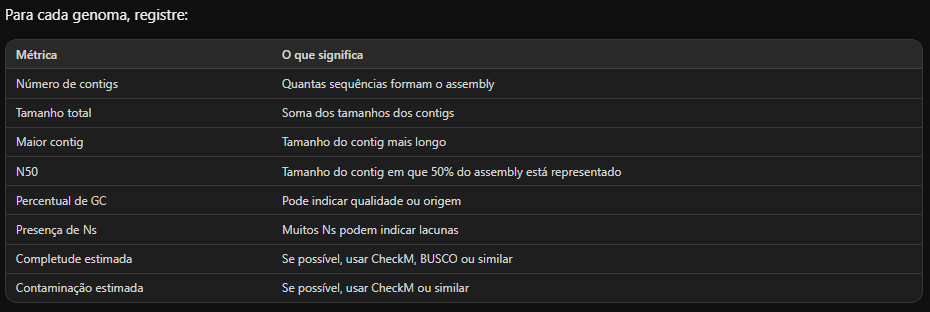

In [20]:
"""
Passo 1: Calcula as métricas físicas fundamentais dos genomas e salva em CSV.
"""
import os
import pandas as pd
from Bio import SeqIO

# --- CONFIGURAÇÃO DE DIRETÓRIOS ---
pasta_genomas = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
pasta_saida_metricas = os.path.join(pasta_genomas, "1_métricas_fundamentais")

def calcular_metricas_assembly(caminho_arquivo):
    try:
        contigs_tamanhos = []
        total_g = 0
        total_c = 0
        total_ns = 0

        # Lê o arquivo e calcula estatísticas iniciais por contig
        for registro in SeqIO.parse(caminho_arquivo, "fasta"):
            seq_str = str(registro.seq).upper()
            tamanho = len(seq_str)
            contigs_tamanhos.append(tamanho)

            # Contagem de bases específicas para GC e Ns
            total_g += seq_str.count('G')
            total_c += seq_str.count('C')
            total_ns += seq_str.count('N')

        if not contigs_tamanhos:
            return None

        # Ordena os contigs do maior para o menor para calcular o N50
        contigs_tamanhos.sort(reverse=True)
        tamanho_total = sum(contigs_tamanhos)
        maior_contig = contigs_tamanhos[0]
        n_contigs = len(contigs_tamanhos)

        # Cálculo do N50
        metade_tamanho = tamanho_total / 2.0
        soma_acumulada = 0
        n50 = 0
        for tam in contigs_tamanhos:
            soma_acumulada += tam
            if soma_acumulada >= metade_tamanho:
                n50 = tam
                break

        # Cálculo do Percentual de GC
        percentual_gc = ((total_g + total_c) / (tamanho_total - total_ns)) * 100 if (tamanho_total - total_ns) > 0 else 0.0

        # Avaliação inicial de tamanho esperado
        status_tamanho = "Esperado (3.5 - 6.0 Mb)" if 3500000 <= tamanho_total <= 6000000 else "Desvio Detectado"

        return {
            "Arquivo": os.path.basename(caminho_arquivo),
            "Número de Contigs": n_contigs,
            "Tamanho Total (pb)": tamanho_total,
            "Tamanho Total (Mb)": round(tamanho_total / 1e6, 2),
            "Maior Contig (pb)": maior_contig,
            "N50 (pb)": n50,
            "Percentual GC (%)": round(percentual_gc, 2),
            "Quantidade de Ns": total_ns,
            "Status Tamanho": status_tamanho
        }
    except Exception as e:
        print(f"Erro ao processar o arquivo {caminho_arquivo}: {e}")
        return None

# --- 1. PROCESSAMENTO FÍSICO DOS GENOMAS ---
print("=== INICIANDO ANÁLISE DE QUALIDADE FÍSICA (FASTA/FNA) ===")
extensoes_validas = (".fasta", ".fna", ".fa")
arquivos_genomas = [os.path.join(pasta_genomas, f) for f in os.listdir(pasta_genomas) if f.lower().endswith(extensoes_validas)]

resultados_qc = []
for arq in arquivos_genomas:
    metas = calcular_metricas_assembly(arq)
    if metas:
        resultados_qc.append(metas)

if not resultados_qc:
    print(f"Nenhum arquivo de genoma localizado em: {pasta_genomas}")
else:
    df_qc = pd.DataFrame(resultados_qc)
    print(f"Métricas físicas calculadas para {len(df_qc)} genomas.")

    # Cria a subpasta caso não exista
    os.makedirs(pasta_saida_metricas, exist_ok=True)

    # Caminho final do arquivo de saída
    caminho_csv_saida = os.path.join(pasta_saida_metricas, "métricas_fundamentais.csv")

    # Salva o DataFrame em arquivo CSV
    df_qc.to_csv(caminho_csv_saida, index=False, encoding='utf-8')
    print(f"Métricas salvas com sucesso em: {caminho_csv_saida}")
    display(df_qc.head())

=== INICIANDO ANÁLISE DE QUALIDADE FÍSICA (FASTA/FNA) ===
Métricas físicas calculadas para 774 genomas.
Métricas salvas com sucesso em: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos/1_métricas_fundamentais/métricas_fundamentais.csv


,Arquivo,Número de Contigs,Tamanho Total (pb),Tamanho Total (Mb),Maior Contig (pb),N50 (pb),Percentual GC (%),Quantidade de Ns,Status Tamanho
0,GCA_019038955.3_ASM1903895v3_genomic.fna,46,4890415,4.89,542453,238900,52.22,0,Esperado (3.5 - 6.0 Mb)
1,GCA_019038795.2_ASM1903879v2_genomic.fna,33,4696281,4.70,1081635,416750,52.25,0,Esperado (3.5 - 6.0 Mb)
2,GCA_019807815.1_PDT001119057.1_genomic.fna,60,5244860,5.24,450387,229809,51.99,0,Esperado (3.5 - 6.0 Mb)
3,GCA_019807575.1_PDT001119038.1_genomic.fna,46,5315401,5.32,524952,235297,51.99,0,Esperado (3.5 - 6.0 Mb)
4,GCA_019807835.1_PDT001119030.1_genomic.fna,54,5354656,5.35,516248,226694,51.96,0,Esperado (3.5 - 6.0 Mb)


______________________________________________________

## Critérios de inclusão e exclusão

Critérios obrigatórios definidos:

1. Espécie deve ser Salmonella enterica.
2. O arquivo deve ser um assembly de genoma, não apenas genes.
3. O tamanho total deve estar dentro de uma faixa plausível.
4. O genoma não pode estar vazio ou corrompido.
5. País de origem sendo Brasil.
6. Sem restrição de ano.
7. Sem restrição quanto a fonte de coleta.


Critérios recomendados definidos para o projeto:

1. Completude ≥ 90%, se possível.
2. N50 ≥ 50 kb ou 100 kb, dependendo da qualidade do conjunto.
3. Número de contigs não muito alto, por exemplo < 500 ou < 1000.
4. Percentual de Ns baixo.
5. Metadados essenciais completos.

Decisão a ser tomada:

*   Espécie diferente de Salmonella enterica =	Excluir
* Arquivo vazio ou corrompido =	Excluir
* Tamanho muito abaixo de 3,5 Mb =	Excluir ou revisar
* País faltando =	Colocar em grupo “desconhecido” ou excluir
* Ano faltando = Colocar em grupo “desconhecido” ou excluir
* Duplicata exata =	Manter apenas uma
* Duplicata quase idêntica =	Escolher a de melhor qualidade

In [21]:
"""
Passo 2: Carrega as métricas salvas em CSV, integra os metadados do NCBI, realiza a filtragem e salva o resultado final.
"""
import os
import pandas as pd

# --- CONFIGURAÇÃO DE DIRETÓRIOS ---
pasta_genomas = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_csv_metricas = os.path.join(pasta_genomas, "1_métricas_fundamentais", "métricas_fundamentais.csv")
pasta_saida_filtragem = os.path.join(pasta_genomas, "2_inclusão_exclusão")

print("=== CARREGANDO MÉTRICAS DE QUALIDADE FÍSICA ===")
if not os.path.exists(caminho_csv_metricas):
    print(f"Erro: O arquivo {caminho_csv_metricas} não foi encontrado. Execute o Passo 1 primeiro!")
else:
    # Carrega as métricas geradas na etapa anterior
    df_qc = pd.read_csv(caminho_csv_metricas)
    print(f"Métricas de {len(df_qc)} genomas carregadas com sucesso.\n")

    # --- 1. Extração do Identificador do Assembly ---
    def obter_id_assembly(nome_arquivo):
        partes = nome_arquivo.split('_')
        if len(partes) >= 2:
            return f"{partes[0]}_{partes[1]}"
        return nome_arquivo

    df_qc['Assembly_ID'] = df_qc['Arquivo'].apply(obter_id_assembly)
    ncbi_df['Assembly_ID'] = ncbi_df['Assembly'].astype(str).str.strip()

    # --- 2. Unificação de Métricas e Metadados ---
    df_consolidado = pd.merge(df_qc, ncbi_df, on='Assembly_ID', how='inner')
    print(f"=== UNIFICAÇÃO DE DADOS ===")
    print(f"Total de genomas cruzados com sucesso com o NCBI: {len(df_consolidado)}")

    # --- 3. Aplicação dos Critérios Obrigatórios ---
    print("\n--- APLICANDO FILTROS OBRIGATÓRIOS ---")
    # Critério 1: Espécie deve ser Salmonella enterica
    filtro_especie = df_consolidado['#Organism group'].str.contains('Salmonella enterica', case=False, na=False)

    # Critérios 2 e 3: Tamanho total do genoma plausível (entre 3.5 Mb e 6.0 Mb)
    filtro_tamanho = (df_consolidado['Tamanho Total (pb)'] >= 3500000) & (df_consolidado['Tamanho Total (pb)'] <= 6000000)

    # Critério 4: Genoma não corrompido/vazio (número de contigs válido)
    filtro_vazio = df_consolidado['Número de Contigs'] > 0

    # Critério 5: País de origem sendo Brasil
    filtro_brasil = df_consolidado['Location'].str.contains('Brazil', case=False, na=False)

    # Aplicando Filtros Obrigatórios
    df_obrigatorios = df_consolidado[filtro_especie & filtro_tamanho & filtro_vazio & filtro_brasil].copy()
    print(f"Genomas aprovados nos critérios obrigatórios (S. enterica, Brasil, tamanho válido): {len(df_obrigatorios)}")

    # --- 4. Tratamento de Metadados Faltantes ---
    df_obrigatorios['Year'] = df_obrigatorios['Year'].fillna('Desconhecido')
    df_obrigatorios['Location'] = df_obrigatorios['Location'].fillna('Brazil: Desconhecido')
    df_obrigatorios['Isolation source'] = df_obrigatorios['Isolation source'].fillna('Desconhecido')

    # --- 5. Tratamento de Duplicatas (Resolução de Qualidade) ---
    # Ordena pelo BioSample e prioriza: maior N50 (1º) e menor número de contigs (2º)
    df_obrigatorios = df_obrigatorios.sort_values(
        by=['BioSample', 'N50 (pb)', 'Número de Contigs'],
        ascending=[True, False, True]
    )

    # Mantém apenas o de melhor qualidade para cada BioSample
    df_sem_duplicatas = df_obrigatorios.drop_duplicates(subset=['BioSample'], keep='first').copy()
    print(f"Genomas restantes após remoção de duplicatas biológicas (BioSample): {len(df_sem_duplicatas)}")

    # --- 6. Avaliação dos Critérios Recomendados (Classificação Fina) ---
    df_sem_duplicatas['Atende_N50_Recomendado'] = df_sem_duplicatas['N50 (pb)'] >= 50000
    df_sem_duplicatas['Atende_Contigs_Recomendado'] = df_sem_duplicatas['Número de Contigs'] < 500
    df_sem_duplicatas['Atende_Ns_Recomendado'] = df_sem_duplicatas['Quantidade de Ns'] < 1000

    # Filtrando para obter o dataset final de altíssima qualidade (Golden Set)
    df_final_excelente = df_sem_duplicatas[
        df_sem_duplicatas['Atende_N50_Recomendado'] &
        df_sem_duplicatas['Atende_Contigs_Recomendado'] &
        df_sem_duplicatas['Atende_Ns_Recomendado']
    ].copy()

    print(f"\nGenomas aprovados no conjunto de EXCELÊNCIA (Obrigatórios + Todos Recomendados): {len(df_final_excelente)}")

    # --- 7. Salvamento do Resultado Final ---
    os.makedirs(pasta_saida_filtragem, exist_ok=True)
    caminho_csv_saida = os.path.join(pasta_saida_filtragem, "inclusão_exclusão.csv")

    df_final_excelente.to_csv(caminho_csv_saida, index=False, encoding='utf-8')
    print(f"Tabela final de inclusão/exclusão salva em: {caminho_csv_saida}")

    # Exibir a tabela final de genomas prontos para a próxima etapa
    display(df_final_excelente[['Arquivo', 'Número de Contigs', 'Tamanho Total (Mb)', 'N50 (pb)', 'Quantidade de Ns', 'Location', 'Year']].head())

=== CARREGANDO MÉTRICAS DE QUALIDADE FÍSICA ===
Métricas de 774 genomas carregadas com sucesso.

=== UNIFICAÇÃO DE DADOS ===
Total de genomas cruzados com sucesso com o NCBI: 774

--- APLICANDO FILTROS OBRIGATÓRIOS ---
Genomas aprovados nos critérios obrigatórios (S. enterica, Brasil, tamanho válido): 774
Genomas restantes após remoção de duplicatas biológicas (BioSample): 774

Genomas aprovados no conjunto de EXCELÊNCIA (Obrigatórios + Todos Recomendados): 716
Tabela final de inclusão/exclusão salva em: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos/2_inclusão_exclusão/inclusão_exclusão.csv


,Arquivo,Número de Contigs,Tamanho Total (Mb),N50 (pb),Quantidade de Ns,Location,Year
143,GCA_023285885.1_PDT001302847.1_genomic.fna,192,4.74,50381,0,Brazil,2022
164,GCA_023237945.1_PDT001298915.1_genomic.fna,65,4.86,236349,0,Brazil,2022
141,GCA_023236925.1_PDT001298916.1_genomic.fna,68,4.87,174054,0,Brazil,2022
163,GCA_023237905.1_PDT001298917.1_genomic.fna,68,4.95,315651,0,Brazil,2022
146,GCA_023237885.1_PDT001298918.1_genomic.fna,62,4.90,323611,0,Brazil,2022


______________________________________________________

## Padronização dos nomes das espécies





Critérios de padronização:
* Criar uma tabela de correspondência
* Usar a nomenclatura do NCBI Taxonomy
* Manter uma coluna original e uma coluna padronizada.

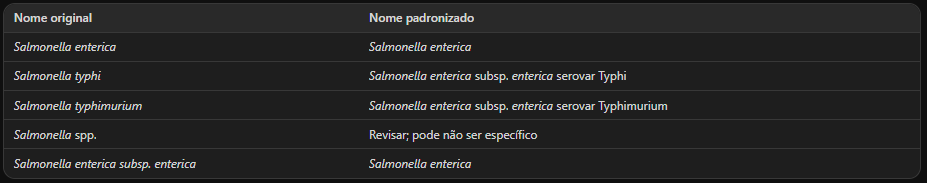

In [24]:

# --- CONFIGURAÇÃO DE CAMINHOS ---
pasta_genomas = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_entrada_filtrados = os.path.join(pasta_genomas, "2_inclusão_exclusão", "inclusão_exclusão.csv")
pasta_saida_padronizacao = os.path.join(pasta_genomas, "3_padronizacao")

print("=== PASSO 1: CARREGANDO OS DADOS ===")
if not os.path.exists(caminho_entrada_filtrados):
    print(f"Erro: O arquivo {caminho_entrada_filtrados} não foi encontrado. Execute o passo anterior primeiro!")
else:
    df_filtrados = pd.read_csv(caminho_entrada_filtrados)
    print(f"Sucesso! {len(df_filtrados)} genomas de excelência carregados.\n")

    print("=== PASSO 2: EXAMINANDO OS NOMES DE ORGANISMOS ORIGINAIS ===")
    # Vamos examinar os nomes únicos presentes na coluna do grupo do organismo
    coluna_organismo = "#Organism group"
    nomes_originais = df_filtrados[coluna_organismo].unique()
    print("Nomes originais encontrados na base de dados:")
    for nome in nomes_originais:
        print(f" - '{nome}'")
    print("\n")

    print("=== PASSO 3: CRIANDO A TABELA DE CORRESPONDÊNCIA ===")
    # Dicionário de mapeamento guiado pela taxonomia oficial do NCBI
    tabela_correspondencia = {
        "Salmonella enterica": "Salmonella enterica",
        "Salmonella enterica subsp. enterica": "Salmonella enterica",
        "Salmonella enterica enterica": "Salmonella enterica",
        # Caso existissem variações de escrita/digitação comuns:
        "salmonella enterica": "Salmonella enterica",
        "Salmonella enterica ": "Salmonella enterica"
    }
    print("Tabela de correspondência criada com sucesso.")
    print(tabela_correspondencia, "\n")

    print("=== PASSO 4: APLICANDO A PADRONIZAÇÃO COM RASTREABILIDADE ===")
    # Criando a coluna com o nome original para fins de auditoria/rastreabilidade
    df_filtrados["Organismo_Original"] = df_filtrados[coluna_organismo]

    # Aplicando a padronização na nova coluna usando a tabela de correspondência

    df_filtrados["Organismo_Padronizado"] = df_filtrados["Organismo_Original"].map(tabela_correspondencia).fillna(df_filtrados["Organismo_Original"])

    print("Padronização concluída.")
    print("Comparação amostral (Original vs Padronizado):")
    display(df_filtrados[["Arquivo", "Organismo_Original", "Organismo_Padronizado"]].head())
    print("\n")

    print("=== PASSO 5: SALVANDO O RESULTADO PADRONIZADO ===")
    os.makedirs(pasta_saida_padronizacao, exist_ok=True)
    caminho_csv_saida = os.path.join(pasta_saida_padronizacao, "padronização_nome.csv")

    df_filtrados.to_csv(caminho_csv_saida, index=False, encoding='utf-8')
    print(f"Tabela padronizada salva com sucesso em: {caminho_csv_saida}")

=== PASSO 1: CARREGANDO OS DADOS ===
Sucesso! 716 genomas de excelência carregados.

=== PASSO 2: EXAMINANDO OS NOMES DE ORGANISMOS ORIGINAIS ===
Nomes originais encontrados na base de dados:
 - 'Salmonella enterica'


=== PASSO 3: CRIANDO A TABELA DE CORRESPONDÊNCIA ===
Tabela de correspondência criada com sucesso.
{'Salmonella enterica': 'Salmonella enterica', 'Salmonella enterica subsp. enterica': 'Salmonella enterica', 'Salmonella enterica enterica': 'Salmonella enterica', 'salmonella enterica': 'Salmonella enterica', 'Salmonella enterica ': 'Salmonella enterica'} 

=== PASSO 4: APLICANDO A PADRONIZAÇÃO COM RASTREABILIDADE ===
Padronização concluída.
Comparação amostral (Original vs Padronizado):


,Arquivo,Organismo_Original,Organismo_Padronizado
0,GCA_023285885.1_PDT001302847.1_genomic.fna,Salmonella enterica,Salmonella enterica
1,GCA_023237945.1_PDT001298915.1_genomic.fna,Salmonella enterica,Salmonella enterica
2,GCA_023236925.1_PDT001298916.1_genomic.fna,Salmonella enterica,Salmonella enterica
3,GCA_023237905.1_PDT001298917.1_genomic.fna,Salmonella enterica,Salmonella enterica
4,GCA_023237885.1_PDT001298918.1_genomic.fna,Salmonella enterica,Salmonella enterica




=== PASSO 5: SALVANDO O RESULTADO PADRONIZADO ===
Tabela padronizada salva com sucesso em: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos/3_padronizacao/padronização_nome.csv


______________________________________________________

## Padronização da fonte do isolado

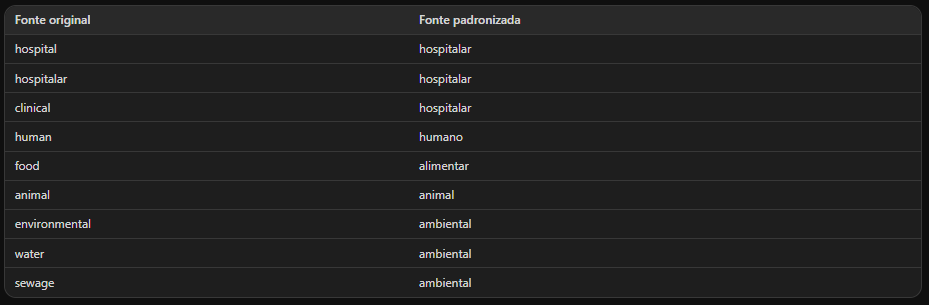

In [26]:
# --- CONFIGURAÇÃO DE CAMINHOS ---
pasta_genomas = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_entrada_nomes = os.path.join(pasta_genomas, "3_padronizacao", "padronização_nome.csv")
pasta_saida_fontes = os.path.join(pasta_genomas, "4_padronização_fonte")
caminho_saida_csv = os.path.join(pasta_saida_fontes, "padronização_fonte.csv")

print("=== PASSO 1: CARREGANDO OS DADOS ===")
if not os.path.exists(caminho_entrada_nomes):
    print(f"Erro: O arquivo {caminho_entrada_nomes} não foi encontrado. Execute o passo anterior primeiro!")
else:
    df_nomes = pd.read_csv(caminho_entrada_nomes)
    print(f"Sucesso! {len(df_nomes)} genomas carregados da etapa anterior.\n")

    print("=== PASSO 2: EXAMINANDO AS FONTES ORIGINAIS (TOP 20) ===")
    # Analisamos os termos mais frequentes antes de mapear
    print(df_nomes["Isolation source"].value_counts(dropna=False).head(20))
    print("\n")

    print("=== PASSO 3: CRIANDO A TABELA DE CORRESPONDÊNCIA ===")
    # Tabela de mapeamento transparente e categórica
    tabela_correspondencia_fontes = {
        # Categorias de Água / Ambiental
        "fresh water stream": "Ambiental (Água)",
        "dam water": "Ambiental (Água)",
        "Stream": "Ambiental (Água)",
        "water": "Ambiental (Água)",
        "fresh water": "Ambiental (Água)",
        "stream": "Ambiental (Água)",
        "water dam": "Ambiental (Água)",

        # Categorias de Origem Animal
        "chicken": "Animal (Avícola)",
        "Poultry (chicken)": "Animal (Avícola)",
        "chicken slaughter houses": "Animal (Avícola)",
        "Poultry litter": "Animal (Avícola)",
        "Drag swab": "Animal (Avícola)",
        "drag swab": "Animal (Avícola)",
        "Animal Rectal Swab": "Animal (Outros)",

        # Categorias Clínicas / Diagnóstico
        "blood": "Clínico (Humano/Animal)",
        "feces": "Clínico (Humano/Animal)",
        "urine": "Clínico (Humano/Animal)",
        "Anal swab": "Clínico (Humano/Animal)",
        "brain": "Clínico (Humano/Animal)",
        "nasal swab": "Clínico (Humano/Animal)",
        "kidney": "Clínico (Humano/Animal)",

        # Categorias de Alimentos
        "carcass": "Alimento (Carne/Processados)",
        "Frozen Chicken Shawrma": "Alimento (Carne/Processados)",
        "food": "Alimento (Geral)"
    }
    print("Tabela de correspondência estruturada com sucesso.\n")

    print("=== PASSO 4: APLICANDO A PADRONIZAÇÃO COM RASTREABILIDADE ===")
    # Criação da coluna de controle original para auditoria
    df_nomes["Fonte_Original"] = df_nomes["Isolation source"].fillna("Desconhecido")

    # Aplica o mapeamento e mantém termos não listados como 'Outros/Desconhecido'
    df_nomes["Fonte_Padronizada"] = df_nomes["Fonte_Original"].map(tabela_correspondencia_fontes).fillna("Outros/Desconhecido")

    print("Tabela de contagem pós-padronização:")
    print(df_nomes["Fonte_Padronizada"].value_counts())
    print("\n")

    print("Comparação para Auditoria (Original vs Padronizado):")
    display(df_nomes[["Arquivo", "Fonte_Original", "Fonte_Padronizada"]].head(15))
    print("\n")

    print("=== PASSO 5: SALVANDO OS RESULTADOS ===")
    os.makedirs(pasta_saida_fontes, exist_ok=True)
    df_nomes.to_csv(caminho_saida_csv, index=False, encoding='utf-8')
    print(f"Tabela padronizada exportada com sucesso para: {caminho_saida_csv}")

=== PASSO 1: CARREGANDO OS DADOS ===
Sucesso! 716 genomas carregados da etapa anterior.

=== PASSO 2: EXAMINANDO AS FONTES ORIGINAIS (TOP 20) ===
Isolation source
Desconhecido                                 146
carcass                                       55
blood                                         51
feces                                         48
dam water                                     46
drag swab                                     31
slaughterhouse                                24
flock environment broiler (Gallus gallus)     20
stool                                         19
food                                          15
urine                                         13
fresh water stream                            13
slaughterhouse (Gallus gallus)                10
chicken                                        9
cleaned track                                  8
Mesenteric Lymph Node                          8
flock environment (Gallus gallus)              8
Gall

,Arquivo,Fonte_Original,Fonte_Padronizada
0,GCA_023285885.1_PDT001302847.1_genomic.fna,Pig marrow,Outros/Desconhecido
1,GCA_023237945.1_PDT001298915.1_genomic.fna,chicken,Animal (Avícola)
2,GCA_023236925.1_PDT001298916.1_genomic.fna,chicken,Animal (Avícola)
3,GCA_023237905.1_PDT001298917.1_genomic.fna,chicken,Animal (Avícola)
4,GCA_023237885.1_PDT001298918.1_genomic.fna,chicken,Animal (Avícola)
5,GCA_023237865.1_PDT001298919.1_genomic.fna,chicken,Animal (Avícola)
6,GCA_023237845.1_PDT001298920.1_genomic.fna,chicken,Animal (Avícola)
7,GCA_011350945.1_PDT000676900.1_genomic.fna,not known,Outros/Desconhecido
8,GCA_011297115.1_PDT000676883.1_genomic.fna,not known,Outros/Desconhecido
9,GCA_000009525.1_ASM952v1_genomic.fna,Desconhecido,Outros/Desconhecido




=== PASSO 5: SALVANDO OS RESULTADOS ===
Tabela padronizada exportada com sucesso para: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos/4_padronização_fonte/padronização_fonte.csv


______________________________________________________

## Remoção de duplicatas



Duplicatas exatas:

* Mesmo nome de accession.
* Mesmo ID de isolado.
* Mesmo tamanho total.
* Mesmo número de contigs.
* Mesma sequência.

Duplicatas quase idênticas:

* O mesmo isolado foi sequenciado duas vezes.
* Genomas muito próximos foram depositados separadamente.
* Assemblys diferentes do mesmo genoma estão presentes.

In [27]:

# --- CONFIGURAÇÃO DE CAMINHOS ---
pasta_genomas = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_entrada_fontes = os.path.join(pasta_genomas, "4_padronização_fonte", "padronização_fonte.csv")
pasta_saida_duplicatas = os.path.join(pasta_genomas, "5_remoção_duplicatas")
caminho_saida_csv = os.path.join(pasta_saida_duplicatas, "remoção_duplicatas.csv")

print("=== PASSO 1: CARREGANDO OS DADOS ===")
if not os.path.exists(caminho_entrada_fontes):
    print(f"Erro: O arquivo {caminho_entrada_fontes} não foi encontrado! Certifique-se de rodar o passo anterior.")
else:
    df_fontes = pd.read_csv(caminho_entrada_fontes)
    total_inicial = len(df_fontes)
    print(f"Sucesso! {total_inicial} genomas carregados da etapa de padronização de fontes.\n")

    print("=== PASSO 2: REMOÇÃO DE DUPLICATAS EXATAS ===")
    # Critérios para duplicata exata na nossa tabela:
    # Mesmo ID de Assembly, mesma amostra (BioSample), mesmo tamanho de genoma e mesmo número de contigs
    colunas_duplicadas_exatas = ['Assembly_ID', 'BioSample', 'Tamanho Total (pb)', 'Número de Contigs']

    # Contamos quantas duplicatas exatas existem
    n_duplicatas_exatas = df_fontes.duplicated(subset=colunas_duplicadas_exatas, keep='first').sum()
    print(f"Duplicatas exatas detectadas (mesma montagem/metadados físicos): {n_duplicatas_exatas}")

    # Removemos mantendo o primeiro registro
    df_sem_exatas = df_fontes.drop_duplicates(subset=colunas_duplicadas_exatas, keep='first').copy()
    total_apos_exatas = len(df_sem_exatas)
    print(f"Genomas restantes após remover duplicatas exatas: {total_apos_exatas}\n")

    print("=== PASSO 3: REMOÇÃO DE DUPLICATAS QUASE IDÊNTICAS (BIOLÓGICAS) ===")
    # Isolados idênticos de re-sequenciamento ou re-montagens compartilham o mesmo identificador biológico (BioSample)
    # Para garantir a escolha da melhor montagem disponível de forma transparente:
    # Ordenamos os dados priorizando: menor número de contigs (1º) e maior N50 (2º)
    df_ordenado = df_sem_exatas.sort_values(
        by=['BioSample', 'Número de Contigs', 'N50 (pb)'],
        ascending=[True, True, False]
    )

    # Identificamos duplicatas quase idênticas (mesmo BioSample)
    n_duplicatas_biologicas = df_ordenado.duplicated(subset=['BioSample'], keep='first').sum()
    print(f"Duplicatas biológicas detectadas (múltiplas montagens do mesmo BioSample): {n_duplicatas_biologicas}")

    # Mantemos apenas a primeira linha (que é a de melhor qualidade física devido à nossa ordenação)
    df_limpo = df_ordenado.drop_duplicates(subset=['BioSample'], keep='first').copy()
    total_final = len(df_limpo)
    print(f"Genomas finais de excelência restantes: {total_final}\n")

    print("=== PASSO 4: RELATÓRIO DO PROCESSO DE HIGIENIZAÇÃO ===")
    print(f"- Tamanho Inicial do Dataset: {total_inicial} genomas")
    print(f"- Remoções de Duplicatas Exatas: {n_duplicatas_exatas} registros eliminados")
    print(f"- Remoções de Duplicatas Quase Idênticas: {n_duplicatas_biologicas} registros eliminados")
    print(f"- Tamanho Final Filtrado: {total_final} genomas únicos e de alta qualidade")
    print(f"- Eficiência de Limpeza: {round((1 - (total_final / total_inicial)) * 100, 2)}% dos registros eram redundantes.\n")

    print("=== PASSO 5: SALVANDO O RESULTADO HIGIENIZADO ===")
    os.makedirs(pasta_saida_duplicatas, exist_ok=True)
    df_limpo.to_csv(caminho_saida_csv, index=False, encoding='utf-8')
    print(f"O arquivo limpo e livre de duplicatas foi salvo em: {caminho_saida_csv}")

=== PASSO 1: CARREGANDO OS DADOS ===
Sucesso! 716 genomas carregados da etapa de padronização de fontes.

=== PASSO 2: REMOÇÃO DE DUPLICATAS EXATAS ===
Duplicatas exatas detectadas (mesma montagem/metadados físicos): 0
Genomas restantes após remover duplicatas exatas: 716

=== PASSO 3: REMOÇÃO DE DUPLICATAS QUASE IDÊNTICAS (BIOLÓGICAS) ===
Duplicatas biológicas detectadas (múltiplas montagens do mesmo BioSample): 0
Genomas finais de excelência restantes: 716

=== PASSO 4: RELATÓRIO DO PROCESSO DE HIGIENIZAÇÃO ===
- Tamanho Inicial do Dataset: 716 genomas
- Remoções de Duplicatas Exatas: 0 registros eliminados
- Remoções de Duplicatas Quase Idênticas: 0 registros eliminados
- Tamanho Final Filtrado: 716 genomas únicos e de alta qualidade
- Eficiência de Limpeza: 0.0% dos registros eram redundantes.

=== PASSO 5: SALVANDO O RESULTADO HIGIENIZADO ===
O arquivo limpo e livre de duplicatas foi salvo em: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos

______________________________________________________

# Identificação genes de resistência via Alinhamento Local (BLASTn)

In [28]:
# Instalação do pacote do BLAST
!apt-get install -y ncbi-blast+

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libmbedtls14t64 libmbedx509-1t64 ncbi-data
The following NEW packages will be installed:
  libmbedtls14t64 libmbedx509-1t64 ncbi-blast+ ncbi-data
0 upgraded, 4 newly installed, 0 to remove and 0 not upgraded.
Need to get 16.9 MB of archives.
After this operation, 73.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 libmbedx509-1t64 amd64 2.28.8-1 [46.6 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libmbedtls14t64 amd64 2.28.8-1 [82.2 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble/universe amd64 ncbi-data all 6.1.20170106+dfsg2-2 [4,281 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble/universe amd64 ncbi-blast+ amd64 2.12.0+ds-4build2 [12.5 MB]
Fetched 16.9 MB in 1s (26.6 MB/s)
Selecting previously unselected package libmbedx509-1t64:amd64.
(Reading database ... 12

In [38]:
import subprocess
import os
import shutil
import pandas as pd
from Bio import SeqIO

# --- CONFIGURAÇÃO DE CAMINHOS ---
pasta_dados = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_duplicatas = os.path.join(pasta_dados, "5_remoção_duplicatas", "remoção_duplicatas.csv")
caminho_card_referencia = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos/Referências CARD/referencia_card_salmonella.csv"
caminho_card_fasta = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos/nucleotide_fasta_protein_homolog_model.fasta"

pasta_saida_amr = os.path.join(pasta_dados, "6_genes_resistencia")
os.makedirs(pasta_saida_amr, exist_ok=True)

# Pasta temporária de processamento rápido e segura contra caminhos com espaços
pasta_temp_exec = "/content/temp_blast_batch"
os.makedirs(pasta_temp_exec, exist_ok=True)

print("=== PASSO 1: CARREGANDO GENOMAS CURADOS E REFERÊNCIA DO CARD ===")
if not os.path.exists(caminho_duplicatas):
    print(f"Erro: O arquivo {caminho_duplicatas} não foi encontrado!")
elif not os.path.exists(caminho_card_fasta):
    print(f"Erro: O arquivo FASTA do CARD {caminho_card_fasta} não foi encontrado!")
else:
    df_genomas = pd.read_csv(caminho_duplicatas)
    print(f"Sucesso! {len(df_genomas)} genomas de excelência prontos para alinhamento.\n")

    # --- FILTRAGEM DO FASTA DO CARD PARA OS GENES DE SALMONELLA ---
    print("=== PASSO 2: FILTRANDO SEQUÊNCIAS DO CARD ESPECÍFICAS DE SALMONELLA ===")
    ref_sal_df = pd.read_csv(caminho_card_referencia)
    aros_validos = set(ref_sal_df["ARO Accession"].dropna().unique())

    card_fasta_filtrado = os.path.join(pasta_saida_amr, "card_salmonella_genes.fasta")
    records_filtrados = []
    for record in SeqIO.parse(caminho_card_fasta, "fasta"):
        for aro in aros_validos:
            if aro in record.description:
                records_filtrados.append(record)
                break

    SeqIO.write(records_filtrados, card_fasta_filtrado, "fasta")
    print(f"Sucesso! Extraídos {len(records_filtrados)} genes de referência do CARD.\n")

    # Copiando arquivo query de referência do CARD para a área livre de espaços
    card_fasta_local = os.path.join(pasta_temp_exec, "card_query.fasta")
    shutil.copy(card_fasta_filtrado, card_fasta_local)

    # --- CONFIGURAÇÃO DOS PARÂMETROS DO BLAST ---
    IDENTIDADE_MINIMA = 95.0
    COBERTURA_MINIMA = 90.0

    print(f"=== PASSO 3 & 4: EXECUTANDO ALINHAMENTOS BLAST EM LOTE ===")
    print(f"Filtros Aplicados: Identidade >= {IDENTIDADE_MINIMA}% | Cobertura >= {COBERTURA_MINIMA}%\n")

    resultados_blast_geral = []
    total_genomas = len(df_genomas)

    # Processando genomas de forma otimizada via área de transição local
    for idx, row in df_genomas.iterrows():
        nome_arquivo = row["Arquivo"]
        caminho_fna_origem = os.path.join(pasta_dados, nome_arquivo)

        if not os.path.exists(caminho_fna_origem):
            continue

        # Copia temporária do arquivo genômico para processar no ambiente local
        caminho_fna_local = os.path.join(pasta_temp_exec, "temp_target.fna")
        shutil.copy(caminho_fna_origem, caminho_fna_local)

        # Definição de nomes de arquivos locais temporários sem espaços
        blast_db_tmp = os.path.join(pasta_temp_exec, "temp_db_exec")
        arquivo_saida_blast = os.path.join(pasta_temp_exec, "temp_out.tsv")

        # Criando o banco temporário de BLAST localmente
        subprocess.run([
            "makeblastdb",
            "-in", caminho_fna_local,
            "-dbtype", "nucl",
            "-out", blast_db_tmp
        ], capture_output=True)

        # Executando o BLASTn localmente
        subprocess.run([
            "blastn",
            "-query", card_fasta_local,
            "-db", blast_db_tmp,
            "-outfmt", "6 qseqid sseqid pident length qlen evalue bitscore",
            "-out", arquivo_saida_blast
        ], capture_output=True)

        # Lendo e filtrando os resultados gerados localmente
        if os.path.exists(arquivo_saida_blast) and os.path.getsize(arquivo_saida_blast) > 0:
            colunas_blast = ["qseqid", "sseqid", "pident", "length", "qlen", "evalue", "bitscore"]
            df_res_temp = pd.read_csv(arquivo_saida_blast, sep="\t", names=colunas_blast)
            df_res_temp["coverage"] = (df_res_temp["length"] / df_res_temp["qlen"]) * 100

            # Filtragem de identidade e cobertura estrita
            df_filtrado_temp = df_res_temp[
                (df_res_temp["pident"] >= IDENTIDADE_MINIMA) &
                (df_res_temp["coverage"] >= COBERTURA_MINIMA)
            ].copy()

            for _, r_blast in df_filtrado_temp.iterrows():
                resultados_blast_geral.append({
                    "Arquivo_Genoma": nome_arquivo,
                    "BioSample": row["BioSample"],
                    "CARD_ID_Sequencia": r_blast["qseqid"],
                    "Identidade_Seq": round(r_blast["pident"], 2),
                    "Cobertura_Seq": round(r_blast["coverage"], 2),
                    "E_Value": r_blast["evalue"],
                    "BitScore": r_blast["bitscore"]
                })

        # Mostra o status do progresso de forma amigável
        if (idx + 1) % 50 == 0 or (idx + 1) == total_genomas:
            print(f"Progresso: {idx + 1}/{total_genomas} genomas processados...")

    print("\n=== PASSO 5 & 6: CONSOLIDAÇÃO DOS DADOS DE RESISTÊNCIA ===")
    if resultados_blast_geral:
        df_amr_final = pd.DataFrame(resultados_blast_geral)
        print(f"[SUCESSO!] Identificados {len(df_amr_final)} genes de resistência que atenderam aos critérios estritos.")

        # Exibindo uma prévia da tabela unificada de auditoria
        display(df_amr_final.head(10))

        # Caminho arquivo de saída
        caminho_csv_final_amr = os.path.join(pasta_saida_amr, "genes_resistência.csv")
        df_amr_final.to_csv(caminho_csv_final_amr, index=False, encoding='utf-8')
        print(f"\nTabela de genes identificados salva de volta no Google Drive em: {caminho_csv_final_amr}")
    else:
        print("Atenção: Nenhum gene passou pelas métricas de corte sob os parâmetros selecionados.")

    # Removendo todos os diretórios temporários locais criados durante o batch run
    shutil.rmtree(pasta_temp_exec, ignore_errors=True)
    print("\nLimpeza de arquivos e bancos locais temporários concluída com sucesso!")

=== PASSO 1: CARREGANDO GENOMAS CURADOS E REFERÊNCIA DO CARD ===
Sucesso! 716 genomas de excelência prontos para alinhamento.

=== PASSO 2: FILTRANDO SEQUÊNCIAS DO CARD ESPECÍFICAS DE SALMONELLA ===
Sucesso! Extraídos 75 genes de referência do CARD.

=== PASSO 3 & 4: EXECUTANDO ALINHAMENTOS BLAST EM LOTE ===
Filtros Aplicados: Identidade >= 95.0% | Cobertura >= 90.0%

Progresso: 50/716 genomas processados...
Progresso: 100/716 genomas processados...
Progresso: 150/716 genomas processados...
Progresso: 200/716 genomas processados...
Progresso: 250/716 genomas processados...
Progresso: 300/716 genomas processados...
Progresso: 350/716 genomas processados...
Progresso: 400/716 genomas processados...
Progresso: 450/716 genomas processados...
Progresso: 500/716 genomas processados...
Progresso: 550/716 genomas processados...
Progresso: 600/716 genomas processados...
Progresso: 650/716 genomas processados...
Progresso: 700/716 genomas processados...
Progresso: 716/716 genomas processados...


,Arquivo_Genoma,BioSample,CARD_ID_Sequencia,Identidade_Seq,Cobertura_Seq,E_Value,BitScore
0,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AE006468.2|+|400860-401325|ARO:3000504|golS,99.14,100.0,0.0,837.0
1,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AE006468.2|-|2039654-2040377|ARO:3000826|sdiA,98.75,100.0,0.0,1286.0
2,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AF144880.1|+|3541-3979|ARO:3002569|AAC(6')-Iy,97.49,100.0,0.0,749.0
3,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AE006468.2|-|397057-398284|ARO:3000789|mdsA,99.19,100.0,0.0,2211.0
4,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AE006468.2|-|392419-393931|ARO:3000791|mdsC,98.48,100.0,0.0,2665.0
5,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AE006468.2|-|393893-397061|ARO:3000790|mdsB,99.40,100.0,0.0,5746.0
6,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|AE006468.2|+|1707351-1707789|ARO:3002571|AA...,97.94,100.0,0.0,760.0
7,GCA_023285885.1_PDT001302847.1_genomic.fna,SAMEA104127853,gb|CP014358.1|-|2161325-2162750|ARO:3001327|MdtK,99.44,100.0,0.0,2588.0
8,GCA_023237945.1_PDT001298915.1_genomic.fna,SAMEA12320369,gb|AE006468.2|+|400860-401325|ARO:3000504|golS,99.57,100.0,0.0,848.0
9,GCA_023237945.1_PDT001298915.1_genomic.fna,SAMEA12320369,gb|AE006468.2|-|2039654-2040377|ARO:3000826|sdiA,98.89,100.0,0.0,1291.0



Tabela de genes identificados salva de volta no Google Drive em: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos/6_genes_resistencia/genes_resistência.csv

Limpeza de arquivos e bancos locais temporários concluída com sucesso!


______________________________________________________

# Etapa 7: Construção da Matriz de Presença/Ausência (Genomas vs Genes)

1. Carregar a lista de **716 genomas validados** (para garantir que mesmo os genomas onde nenhum gene foi detectado apareçam na matriz final preenchidos com zeros).
2. Carregar a planilha unificada de alinhamentos gerada no passo anterior (`identificacao_genes_amr.csv`).
3. Mapear o cruzamento cruzando as amostras nas linhas com os IDs dos genes nas colunas.
4. Preencher as lacunas vazias com `0` e os achados positivos com `1`.

In [40]:
import os
import pandas as pd
import numpy as np

# --- CONFIGURAÇÃO DE CAMINHOS ---
pasta_dados = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_duplicatas = os.path.join(pasta_dados, "5_remoção_duplicatas", "remoção_duplicatas.csv")
caminho_amr_csv = os.path.join(pasta_dados, "6_genes_resistencia", "genes_resistência.csv")

pasta_saida_matriz = os.path.join(pasta_dados, "7_matriz_presenca_ausencia")
os.makedirs(pasta_saida_matriz, exist_ok=True)

print("=== PASSO 1: CARREGANDO GENOMAS E ACHADOS DO BLAST ===")
# 1. Carregamos a lista completa de genomas para garantir o tamanho final correto
df_todos_genomas = pd.read_csv(caminho_duplicatas)
lista_biosamples = df_todos_genomas["BioSample"].unique()
print(f"Total de genomas de referência (BioSamples): {len(lista_biosamples)}")

# 2. Carregamos os resultados gerados pelo BLAST
if not os.path.exists(caminho_amr_csv):
    print("Erro: Arquivo de alinhamentos do BLAST não encontrado. Execute a Etapa 6 primeiro!")
else:
    df_blast = pd.read_csv(caminho_amr_csv)
    print(f"Total de alinhamentos válidos carregados: {len(df_blast)}")

    print("\n=== PASSO 2: CRIANDO A MATRIZ CRUZADA (PIVOT TABLE) ===")
    # Usamos o crosstab do pandas para contar quantas vezes cada gene aparece em cada BioSample
    matriz_counts = pd.crosstab(
        index=df_blast["BioSample"],
        columns=df_blast["CARD_ID_Sequencia"]
    )

    print(f"Dimensões iniciais da matriz de contagens: {matriz_counts.shape[0]} amostras x {matriz_counts.shape[1]} genes")

    print("\n=== PASSO 3: REINDEXAÇÃO E TRATAMENTO DE AMOSTRAS SEM GENES ===")
    # Pode ocorrer de algumas amostras não terem nenhum gene identificado.
    # Para manter a integridade estatística do projeto, incluímos essas amostras preenchidas com zeros.
    matriz_reindexada = matriz_counts.reindex(index=lista_biosamples, fill_value=0)
    print(f"Dimensões após garantir todos os {len(lista_biosamples)} genomas: {matriz_reindexada.shape[0]} amostras x {matriz_reindexada.shape[1]} genes")

    print("\n=== PASSO 4: BINARIZAÇÃO (CONVERSÃO PARA 0 E 1) ===")
    # Se um gene foi detectado mais de uma vez (ex: duplicado no genoma), convertemos para 1.
    matriz_binaria = (matriz_reindexada > 0).astype(int)

    # Vamos renomear o índice para ficar claro
    matriz_binaria.index.name = "BioSample"

    print("\n=== PASSO 5: AUDITORIA RÁPIDA DA MATRIZ ===")
    # Quantidade de genes detectados por amostra (soma das linhas)
    genes_por_amostra = matriz_binaria.sum(axis=1)
    print(f"Média de genes de resistência por genoma: {genes_por_amostra.mean():.2f}")
    print(f"Máximo de genes em uma única amostra: {genes_por_amostra.max()}")
    print(f"Mínimo de genes em uma única amostra: {genes_por_amostra.min()}")

    # Exibindo os primeiros resultados da matriz
    print("\nPrévia da Matriz de Presença/Ausência (Primeiras linhas/colunas):")
    display(matriz_binaria.iloc[:10, :5])

    print("\n=== PASSO 6: SALVANDO MATRIZ NO GOOGLE DRIVE ===")
    caminho_matriz_csv = os.path.join(pasta_saida_matriz, "matriz_presenca_ausencia_amr.csv")
    matriz_binaria.to_csv(caminho_matriz_csv)
    print(f"[SUCESSO] Matriz binária salva perfeitamente em: {caminho_matriz_csv}")

=== PASSO 1: CARREGANDO GENOMAS E ACHADOS DO BLAST ===
Total de genomas de referência (BioSamples): 716
Total de alinhamentos válidos carregados: 8557

=== PASSO 2: CRIANDO A MATRIZ CRUZADA (PIVOT TABLE) ===
Dimensões iniciais da matriz de contagens: 716 amostras x 43 genes

=== PASSO 3: REINDEXAÇÃO E TRATAMENTO DE AMOSTRAS SEM GENES ===
Dimensões após garantir todos os 716 genomas: 716 amostras x 43 genes

=== PASSO 4: BINARIZAÇÃO (CONVERSÃO PARA 0 E 1) ===

=== PASSO 5: AUDITORIA RÁPIDA DA MATRIZ ===
Média de genes de resistência por genoma: 10.08
Máximo de genes em uma única amostra: 24
Mínimo de genes em uma única amostra: 4

Prévia da Matriz de Presença/Ausência (Primeiras linhas/colunas):


CARD_ID_Sequencia,gb|AAAGNS010000063.1|-|144-1005|ARO:3000966|TEM-103,gb|AE006468.2|+|1707351-1707789|ARO:3002571|AAC(6')-Iaa,gb|AE006468.2|+|400860-401325|ARO:3000504|golS,gb|AE006468.2|-|2039654-2040377|ARO:3000826|sdiA,gb|AE006468.2|-|392419-393931|ARO:3000791|mdsC
BioSample,,,,,
SAMEA104127853,0,1,1,1,1
SAMEA12320369,0,1,1,1,1
SAMEA12320375,0,1,1,1,1
SAMEA12320383,0,1,1,1,1
SAMEA12320385,0,1,1,1,1
SAMEA12320529,0,1,1,1,1
SAMEA12320534,0,1,1,1,1
SAMEA1462606,0,1,0,1,0
SAMEA1462618,0,1,0,1,0



=== PASSO 6: SALVANDO MATRIZ NO GOOGLE DRIVE ===
[SUCESSO] Matriz binária salva perfeitamente em: /content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos/7_matriz_presenca_ausencia/matriz_presenca_ausencia_amr.csv


______________________________________________________

# Análises exploratórias e estatísticas

### 8.1. Abundância Geral e Prevalência de Genes de Resistência

Nesta primeira subetapa, calculamos a carga geral de resistência (número de genes por genoma) e determinamos quais genes individuais são os mais prevalentes na população amostrada.

=== ESTATÍSTICAS DESCRITIVAS: ABUNDÂNCIA DE GENES ===
count    716.000000
mean      10.078212
std        3.853546
min        4.000000
25%        8.000000
50%        9.000000
75%       10.000000
max       24.000000
dtype: float64

=== TOP 15 GENES MAIS PREVALENTES ===


,Gene,Prevalencia (%)
0,gb|AE006468.2|+|1707351-1707789|ARO:3002571|AA...,100.000000
1,gb|AF144880.1|+|3541-3979|ARO:3002569|AAC(6')-Iy,100.000000
2,gb|AE006468.2|-|2039654-2040377|ARO:3000826|sdiA,100.000000
3,gb|CP014358.1|-|2161325-2162750|ARO:3001327|MdtK,99.162011
4,gb|AE006468.2|-|397057-398284|ARO:3000789|mdsA,93.854749
5,gb|AE006468.2|+|400860-401325|ARO:3000504|golS,93.854749
6,gb|AE006468.2|-|393893-397061|ARO:3000790|mdsB,93.575419
7,gb|AE006468.2|-|392419-393931|ARO:3000791|mdsC,93.575419
8,gb|LAPJ01000014.1|+|36822-37245|ARO:3004113|FosA7,31.983240
9,gb|DQ463751.1|+|75-1221|ARO:3002034|CMY-23,26.117318


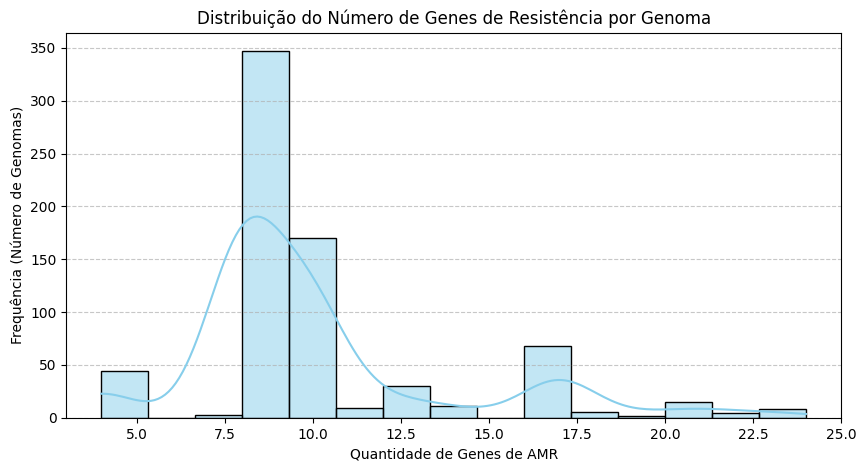

In [41]:

# --- CONFIGURAÇÃO DE CAMINHOS ---
pasta_dados = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/NCBI Salmonella Enterica/data_arquivos"
caminho_matriz = os.path.join(pasta_dados, "7_matriz_presenca_ausencia", "matriz_presenca_ausencia_amr.csv")
caminho_metadados = os.path.join(pasta_dados, "5_remoção_duplicatas", "remoção_duplicatas.csv")
caminho_card_ref = "/content/drive/MyDrive/Colab Notebooks/ResistoMap/CARD Dataset (Referência)/Cruzamento de IDs extraídos/Referências CARD/referencia_card_salmonella.csv"

pasta_saida_estatisticas = os.path.join(pasta_dados, "8_analises_estatisticas")
os.makedirs(pasta_saida_estatisticas, exist_ok=True)

# Carregar matriz binária (amostras nas linhas, genes nas colunas)
matriz_amr = pd.read_csv(caminho_matriz, index_col="BioSample")
total_amostras = len(matriz_amr)

# 1. Abundância Geral (número de genes por genoma)
genes_por_genoma = matriz_amr.sum(axis=1)
print("=== ESTATÍSTICAS DESCRITIVAS: ABUNDÂNCIA DE GENES ===")
print(genes_por_genoma.describe())

# 2. Prevalência de cada Gene
prevalencia_genes = (matriz_amr.sum(axis=0) / total_amostras * 100).sort_values(ascending=False).reset_index()
prevalencia_genes.columns = ["Gene", "Prevalencia (%)"]

print("\n=== TOP 15 GENES MAIS PREVALENTES ===")
display(prevalencia_genes.head(15))

# Salvar prevalência em CSV
prevalencia_genes.to_csv(os.path.join(pasta_saida_estatisticas, "prevalencia_genes.csv"), index=False)

# Visualização da Abundância
plt.figure(figsize=(10, 5))
sns.histplot(genes_por_genoma, kde=True, bins=15, color="skyblue")
plt.title("Distribuição do Número de Genes de Resistência por Genoma")
plt.xlabel("Quantidade de Genes de AMR")
plt.ylabel("Frequência (Número de Genomas)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 8.2. Mapeamento e Prevalência por Classe de Antibióticos

Aqui, cruzamos os cabeçalhos dos genes alinhados com o arquivo de referência consolidado do CARD para extrair a coluna `Drug Class`, permitindo agrupar nossos achados em classes terapêuticas de relevância clínica.

=== PREVALÊNCIA POR CLASSE DE ANTIBIÓTICOS ===


,Classe de Antibiótico,Prevalencia (%)
0,Outros/Desconhecido,100.0


/tmp/ipykernel_887/83069678.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Prevalencia (%)", y="Classe de Antibiótico", data=prevalencia_classes.head(15), palette="viridis")


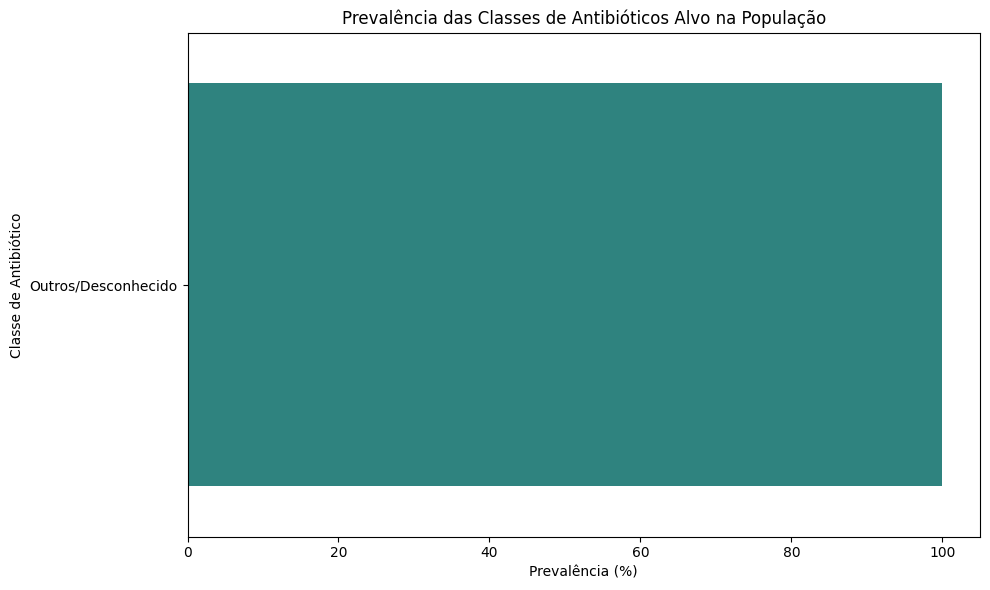

In [42]:
# Carregar metadados do CARD para obter o mapeamento de classes farmacológicas
card_ref = pd.read_csv(caminho_card_ref)

# Criar dicionário de mapeamento: ID_Sequencia -> Drug Class
# Extraímos o CARD_ID a partir da coluna 'fasta_header' ou 'CARD_ID' correspondente
mapeamento_droga = {}
for _, row in card_ref.iterrows():
    header = row.get("fasta_header")
    drug_class = row.get("Drug Class", "Desconhecido")
    if pd.notna(header) and pd.notna(drug_class):
        mapeamento_droga[header] = drug_class

# Mapear as colunas da matriz para suas respectivas classes
classes_por_gene = []
for col in matriz_amr.columns:
    classe = mapeamento_droga.get(col, "Outros/Desconhecido")
    classes_por_gene.append(classe)

# Criar uma matriz de presença/ausência por Classe de Droga
matriz_classes = pd.DataFrame(index=matriz_amr.index)

for gene_col, classe_str in zip(matriz_amr.columns, classes_por_gene):
    # Como um gene pode pertencer a múltiplas classes separadas por ';', quebramos e atribuímos
    classes_individuais = [c.strip() for c in str(classe_str).split(";") if c.strip()]
    for cl in classes_individuais:
        if cl not in matriz_classes.columns:
            matriz_classes[cl] = matriz_amr[gene_col]
        else:
            # Se múltiplos genes cobrirem a mesma classe, fazemos uma operação OR lógica
            matriz_classes[cl] = (matriz_classes[cl] | matriz_amr[gene_col])

# Calcular prevalência por Classe de Droga
prevalencia_classes = (matriz_classes.sum(axis=0) / total_amostras * 100).sort_values(ascending=False).reset_index()
prevalencia_classes.columns = ["Classe de Antibiótico", "Prevalencia (%)"]

print("=== PREVALÊNCIA POR CLASSE DE ANTIBIÓTICOS ===")
display(prevalencia_classes.head(15))

# Salvar dados de classes
prevalencia_classes.to_csv(os.path.join(pasta_saida_estatisticas, "prevalencia_classes_antibioticos.csv"), index=False)

# Gráfico de prevalência das classes
plt.figure(figsize=(10, 6))
sns.barplot(x="Prevalencia (%)", y="Classe de Antibiótico", data=prevalencia_classes.head(15), palette="viridis")
plt.title("Prevalência das Classes de Antibióticos Alvo na População")
plt.xlabel("Prevalência (%)")
plt.ylabel("Classe de Antibiótico")
plt.tight_layout()
plt.show()

### 8.3. Comparação de Carga de Resistência entre Grupos Epidemiológicos

Nesta etapa, cruzamos as contagens de genes de resistência de cada amostra com as variáveis categóricas de **Fonte Padronizada** e **Ano**, realizando o teste não-paramétrico de Kruskal-Wallis para verificar se as diferenças observadas entre os grupos possuem significância estatística ($p < 0.05$).

=== COMPARAÇÃO POR FONTE PADRONIZADA ===


,count,mean,std,min,25%,50%,75%,max
Fonte_Padronizada,,,,,,,,
Alimento (Carne/Processados),55.0,12.345455,4.164302,8.0,8.0,10.0,17.0,22.0
Alimento (Geral),15.0,10.400000,2.823372,8.0,9.0,10.0,10.0,18.0
Ambiental (Água),60.0,8.216667,0.865373,7.0,8.0,8.0,8.0,13.0
Animal (Avícola),41.0,10.146341,4.430355,8.0,8.0,8.0,9.0,23.0
Clínico (Humano/Animal),112.0,8.080357,4.135407,4.0,4.0,8.0,8.0,21.0
Outros/Desconhecido,433.0,10.547344,3.666439,4.0,8.0,10.0,10.0,24.0



Teste de Kruskal-Wallis para Fontes: Estatística = 115.9304, p-valor = 2.2821e-23
Resultado: Diferença estatisticamente significativa entre as fontes de isolamento!


/tmp/ipykernel_887/3215434552.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Fonte_Padronizada", y="Abundancia", data=df_analise_grupos, palette="Set2")


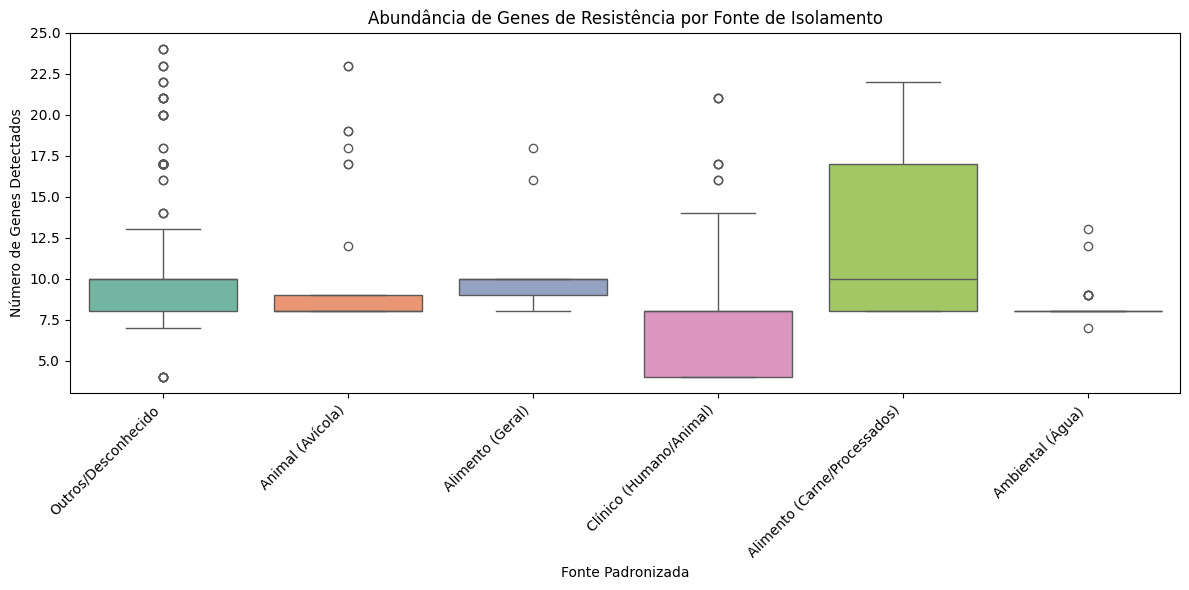

In [43]:
# Carregar metadados dos genomas contendo as fontes padronizadas e anos
df_metadados = pd.read_csv(caminho_metadados)

# Unir a contagem total de genes (abundância) com as variáveis categóricas
df_analise_grupos = pd.DataFrame({
    "BioSample": genes_por_genoma.index,
    "Abundancia": genes_por_genoma.values
})

df_analise_grupos = pd.merge(df_analise_grupos, df_metadados[["BioSample", "Fonte_Padronizada", "Year"]], on="BioSample", how="inner")

# 1. Comparação por Fonte Padronizada
print("=== COMPARAÇÃO POR FONTE PADRONIZADA ===")
grupos_fonte = df_analise_grupos.groupby("Fonte_Padronizada")["Abundancia"]
display(grupos_fonte.describe())

# Teste estatístico de Kruskal-Wallis para Fontes
listas_fontes = [grupo.values for nome, grupo in grupos_fonte if len(grupo) > 5]
stat_f, p_f = stats.kruskal(*listas_fontes)
print(f"\nTeste de Kruskal-Wallis para Fontes: Estatística = {stat_f:.4f}, p-valor = {p_f:.4e}")
if p_f < 0.05:
    print("Resultado: Diferença estatisticamente significativa entre as fontes de isolamento!")
else:
    print("Resultado: Não há evidência de diferença significativa entre as fontes.")

# Boxplot por Fonte
plt.figure(figsize=(12, 6))
sns.boxplot(x="Fonte_Padronizada", y="Abundancia", data=df_analise_grupos, palette="Set2")
plt.title("Abundância de Genes de Resistência por Fonte de Isolamento")
plt.xlabel("Fonte Padronizada")
plt.ylabel("Número de Genes Detectados")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 8.4. Coocorrência de Genes de Resistência e Agrupamento Hierárquico

Para evidenciar perfis de resistência sinérgicos ou genes possivelmente localizados na mesma plataforma móvel (como plasmídeos), calculamos o índice de coocorrência baseado na similaridade de Jaccard e plotamos um clustered heatmap.

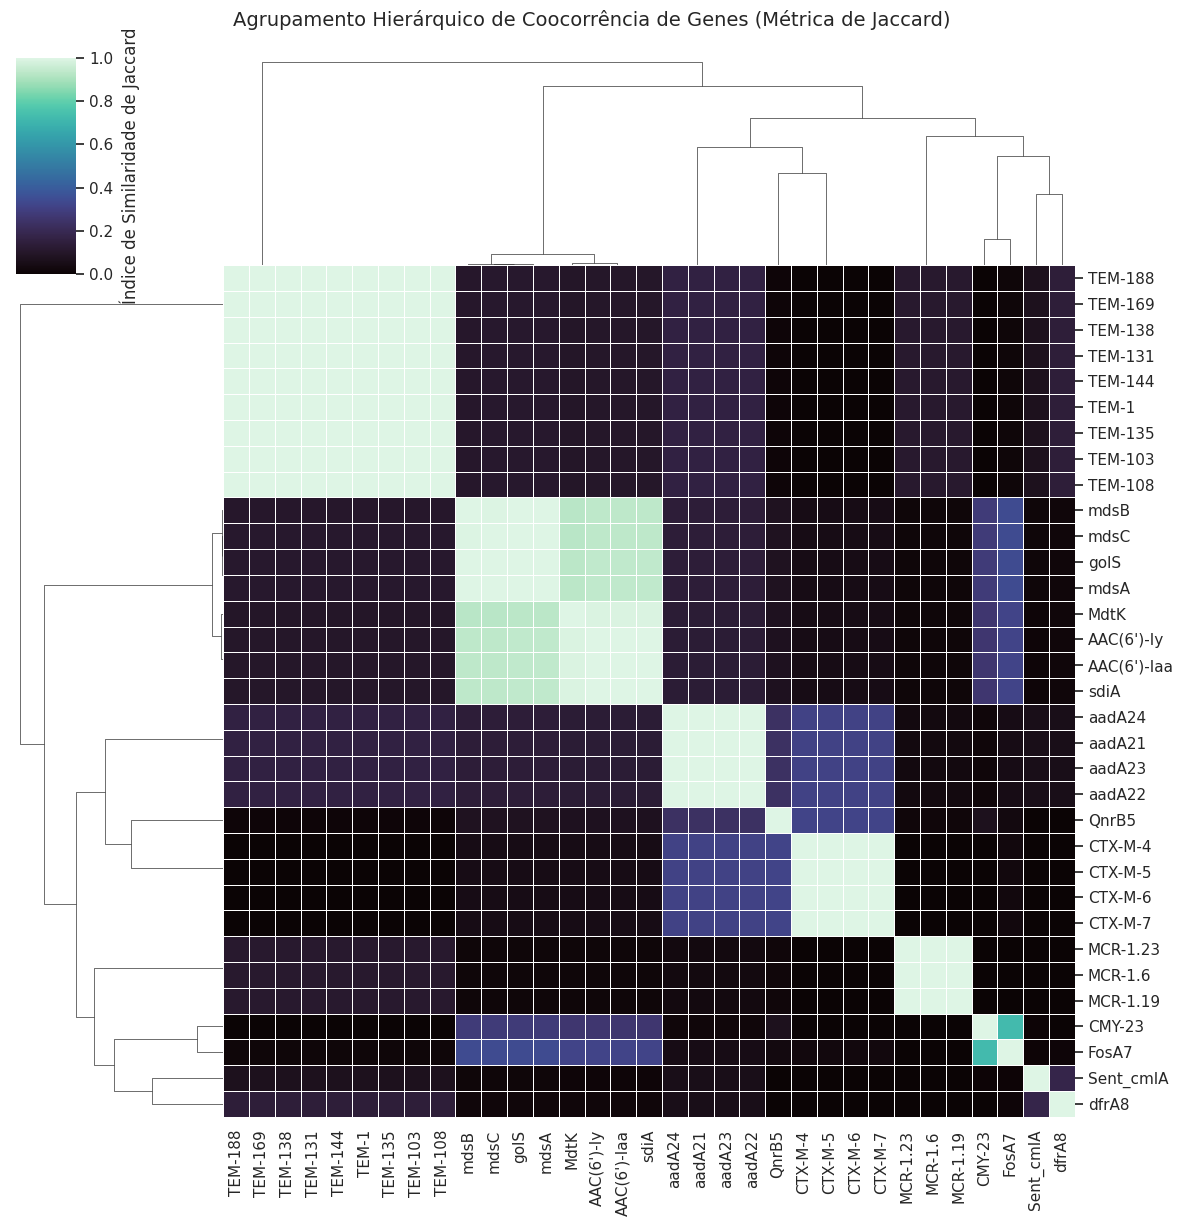

In [44]:
from scipy.spatial.distance import pdist, squareform

# Filtrar genes com baixíssima variação para otimizar a visualização (ex: presentes em pelo menos 1% das amostras)
genes_filtrados = matriz_amr.loc[:, matriz_amr.sum(axis=0) >= (0.01 * total_amostras)]

# Calcular a matriz de distância/similaridade de Jaccard entre colunas (genes)
# pdist calcula distância. Distância de Jaccard = 1 - Similaridade de Jaccard
array_dist = pdist(genes_filtrados.T.values, metric="jaccard")
matriz_dist = squareform(array_dist)

# Similaridade de Jaccard = 1 - Distância
matriz_jaccard = 1 - matriz_dist

# Converter para DataFrame estruturado
# Simplificar nomes para melhor leitura no plot (extraindo apenas o nome do gene no final do ID do CARD)
nomes_curtos = [col.split("|")[-1] for col in genes_filtrados.columns]
df_jaccard = pd.DataFrame(matriz_jaccard, index=nomes_curtos, columns=nomes_curtos)

# Salvar matriz de coocorrência
df_jaccard.to_csv(os.path.join(pasta_saida_estatisticas, "matriz_coocorrencia_jaccard.csv"))

# Gerar o Heatmap com Agrupamento Hierárquico (Clustermap)
sns.set_theme(style="white")
g = sns.clustermap(
    df_jaccard,
    cmap="mako",
    vmin=0, vmax=1,
    linewidths=.5,
    figsize=(12, 12),
    cbar_kws={'label': 'Índice de Similaridade de Jaccard'}
)
g.fig.suptitle("Agrupamento Hierárquico de Coocorrência de Genes (Métrica de Jaccard)", y=1.02, fontsize=14)
plt.show()